# Seclusion EDA — CRDC 2021-22 (school level)
**Task:** explore the cleaned 2021-22 CRDC data to understand seclusion patterns, data completeness, and how school characteristics, staffing and student population relate to seclusion; agree a target definition and feature shortlist. Same structure as the 2017-18 and 2015-16 notebooks so results are comparable.

**Inputs:** `schools_202122.csv` (all schools), `schools_202122_analysis.csv` (rows with `flag_analysis_ready`), `quality_detail_202122.csv` (cleaning log). The cross-year section also reads `schools_201718_analysis.csv` and `crdc_2015_16_analysis_ready.csv`.

**What differs from 2017-18:** the schema is identical, but 2021-22 has a populated virtual-school indicator, much higher missingness for Section 504 and English-learner counts, almost no nonbinary counts, and a much looser FTE outlier flag. 2020-21 was not supplied, so the COVID check in the checklist is flagged as open (section 10).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

DATA_DIR = Path('/mnt/user-data/uploads')   # <- change to the repo data folder
ID = {'combokey': str, 'leaid': str, 'schid': str}   # keep leading zeros
full = pd.read_csv(DATA_DIR/'schools_202122.csv', low_memory=False, dtype=ID)
ana  = pd.read_csv(DATA_DIR/'schools_202122_analysis.csv', low_memory=False, dtype=ID)
qlog = pd.read_csv(DATA_DIR/'quality_detail_202122.csv', low_memory=False, dtype=str)
print('full', full.shape, '| analysis', ana.shape, '| quality log', qlog.shape)

full (98010, 50) | analysis (93094, 50) | quality log (488193, 11)

## 1. Load and validate (checklist 1)
The QA report (`qa_202122.md`) lists the roster count (98,010) and states the analysis-ready count (93,094) was recomputed rather than matched to an audit; both are re-checked here together with internal consistency and the cleaning log.

In [2]:
checks = {
 'years present': full.year.unique().tolist(),
 'rows full / analysis': (len(full), len(ana)),
 'combokey unique (full)': full.combokey.is_unique,
 'combokey == leaid + schid (12 chars, zero-padded)': bool((full.combokey == full.leaid + full.schid).all() and full.combokey.str.len().eq(12).all()),
 'analysis rows all in full': bool(ana.combokey.isin(full.combokey).all()),
 'flag_analysis_ready == (~missing_secl & ~missing_enr)': bool((full.flag_analysis_ready == (~full.flag_missing_seclusion & ~full.flag_missing_enrollment)).all()),
 'analysis file == rows with flag_analysis_ready': int(full.flag_analysis_ready.sum()) == len(ana),
 'seclusion_instances == sum of 3 components (max abs diff)': float((full.seclusion_instances - full[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum(axis=1, min_count=3)).abs().max()),
 'seclusion_rate == instances/enrollment*100 (max abs diff)': float((full.seclusion_rate - full.seclusion_instances/full.enrollment_total*100).abs().max()),
 'states (incl. DC)': full.lea_state.nunique(), 'districts': full.leaid.nunique(),
}
pd.Series(checks, name='result').to_frame()

,result
years present,[2021-22]
rows full / analysis,"(98010, 93094)"
combokey unique (full),True
"combokey == leaid + schid (12 chars, zero-padded)",True
analysis rows all in full,True
flag_analysis_ready == (~missing_secl & ~missing_enr),True
analysis file == rows with flag_analysis_ready,True
seclusion_instances == sum of 3 components (max abs diff),0.000
seclusion_rate == instances/enrollment*100 (max abs diff),0.000
states (incl. DC),52


In [3]:
# Columns that are completely empty, and flags that never fire
empty_cols = full.columns[full.isna().all()].tolist()
dead_flags = [c for c in full.columns if c.startswith('flag_') and full[c].sum()==0]
print('Entirely empty columns :', empty_cols)
print('Flags that never fire  :', dead_flags)
print()
print('Flag counts (full file):'); print(full.filter(like='flag_').sum().to_string())

Entirely empty columns : []
Flags that never fire  : ['flag_missing_module', 'flag_missing_lea']

Flag counts (full file):
flag_missing_seclusion      4905
flag_missing_enrollment     1897
flag_small_enrollment       1290
flag_fte_outlier               1
flag_partial_enrollment    95656
flag_partial_idea          93935
flag_partial_504           93671
flag_partial_el            93127
flag_missing_module            0
flag_missing_lea               0
flag_analysis_ready        93094

In [4]:
# Reconcile the cleaning log (reserved_code / set_to_NA) with the NaNs actually present in the schools file
set_na = qlog[qlog.action.eq('set_to_NA')].groupby('raw_column').size()
mapping = {'SCH_RSINSTANCES_SECL_WODIS':'seclusion_instances_wodis','SCH_RSINSTANCES_SECL_IDEA':'seclusion_instances_idea','SCH_RSINSTANCES_SECL_504':'seclusion_instances_504',
           'SCH_ENR_IDEA_M':'enr_idea','SCH_ENR_504_M':'enr_504','SCH_ENR_EL_M':'enr_el','TOT_ENR_F':'enrollment_total',
           'SCH_FTESECURITY_GUA':'fte_guards','SCH_FTESECURITY_LEO':'fte_leo','SCH_FTESERVICES_NUR':'fte_nurses','SCH_FTESERVICES_PSY':'fte_psych',
           'SCH_FTESERVICES_SOC':'fte_social','SCH_FTECOUNSELORS':'fte_counselors','SCH_FTETEACH_TOT':'fte_teachers'}
rec = pd.DataFrame({'log_set_to_NA': {v: int(set_na.get(k, 0)) for k, v in mapping.items()}, 'nan_in_full_file': {v: int(full[v].isna().sum()) for v in mapping.values()}})
rec['diff'] = rec.log_set_to_NA - rec.nan_in_full_file
print('Log issue/action counts:'); print(qlog.groupby(['issue','action']).size().to_string())
print('\nLog rows with a combokey missing from the schools file:', int((qlog.combokey.notna() & ~qlog.combokey.isin(full.combokey)).sum()), '| rows with no combokey:', int(qlog.combokey.isna().sum()))
print('Non-digit IDs (state-operated programs): schools', int(full.combokey.str.contains('[A-Za-z]').sum()), '| in analysis file', int(ana.combokey.str.contains('[A-Za-z]').sum()))
rec

Log issue/action counts:
issue                 action          
fte_review_threshold  retained                 1
fte_review_top10      retained                70
non_digit_id          kept_as_reported       205
reserved_code         set_to_NA           487917

Log rows with a combokey missing from the schools file: 0 | rows with no combokey: 5
Non-digit IDs (state-operated programs): schools 25 | in analysis file 14

,log_set_to_NA,nan_in_full_file,diff
seclusion_instances_wodis,4905,4905,0
seclusion_instances_idea,4905,4905,0
seclusion_instances_504,4905,4905,0
enr_idea,4126,4126,0
enr_504,22169,22169,0
enr_el,18461,18461,0
enrollment_total,1886,1886,0
fte_guards,2468,2468,0
fte_leo,886,886,0
fte_nurses,3,3,0


## 2. Missing values (checklist 2)
One school year in this file. Seclusion is missing when any of the three component counts is a reserved code.

In [5]:
miss = pd.DataFrame({'n_missing': full.isna().sum(), 'pct_missing': full.isna().mean()*100})
miss = miss[miss.n_missing > 0].sort_values('pct_missing', ascending=False)
miss

,n_missing,pct_missing
enr_nonbinary,95656,97.598
pct_504,22169,22.619
enr_504,22169,22.619
enr_el,18461,18.836
pct_el,18461,18.836
seclusion_rate,4916,5.016
seclusion_instances_idea,4905,5.005
seclusion_instances_wodis,4905,5.005
seclusion_instances_504,4905,5.005
seclusion_instances,4905,5.005


Number of missing seclusion components per school:
0    93105
3     4905

Schools with total missing but >=1 observed component > 0 (lower bound is known): 0
Schools with total missing, 1-2 components missing, all observed components == 0: 0

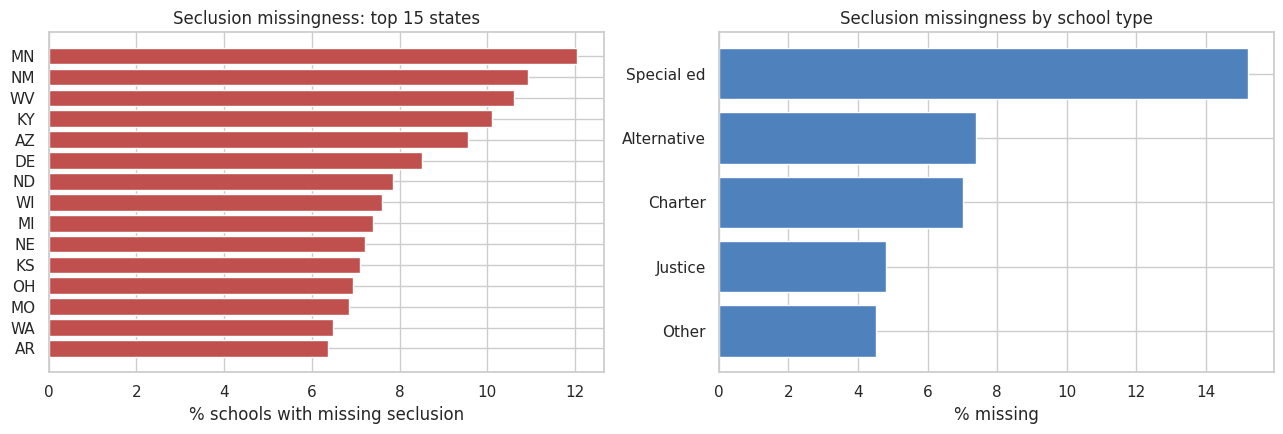

In [6]:
# How is seclusion missingness structured?
comp = ['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']
n_comp_missing = full[comp].isna().sum(axis=1)
print('Number of missing seclusion components per school:'); print(n_comp_missing.value_counts().sort_index().to_string())
part = full[full.seclusion_instances.isna() & (full[comp].fillna(0).sum(axis=1) > 0)]
print(f'\nSchools with total missing but >=1 observed component > 0 (lower bound is known): {len(part)}')
print(f'Schools with total missing, 1-2 components missing, all observed components == 0: {int(((n_comp_missing.between(1,2)) & (full[comp].fillna(0).sum(axis=1)==0)).sum())}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
st = full.groupby('lea_state').flag_missing_seclusion.agg(['mean','sum']).sort_values('mean', ascending=False).head(15)
ax[0].barh(st.index[::-1], st['mean'][::-1]*100, color='#c0504d'); ax[0].set_xlabel('% schools with missing seclusion'); ax[0].set_title('Seclusion missingness: top 15 states')
tmp = full.assign(type=np.select([full.sch_status_sped.eq('Yes'), full.jj.eq('Yes'), full.sch_status_alt.eq('Yes'), full.sch_status_charter.eq('Yes')], ['Special ed','Justice','Alternative','Charter'], 'Other'))
t = tmp.groupby('type').flag_missing_seclusion.mean().sort_values()*100
ax[1].barh(t.index, t.values, color='#4f81bd'); ax[1].set_xlabel('% missing'); ax[1].set_title('Seclusion missingness by school type'); plt.tight_layout()

In [7]:
# Does dropping missing rows bias the analysis file? (full-file profile of missing vs non-missing)
prof = full.assign(any_flag=full.flag_missing_seclusion).groupby('any_flag').agg(
    n=('combokey','size'), median_enr=('enrollment_total','median'), mean_pct_idea=('pct_idea','mean'),
    pct_sped=('sch_status_sped', lambda s:(s=='Yes').mean()*100), pct_charter=('sch_status_charter', lambda s:(s=='Yes').mean()*100),
    pct_alt=('sch_status_alt', lambda s:(s=='Yes').mean()*100), pct_jj=('jj', lambda s:(s=='Yes').mean()*100))
prof

,n,median_enr,mean_pct_idea,pct_sped,pct_charter,pct_alt,pct_jj
any_flag,,,,,,,
False,93105,412.000,16.435,1.648,7.697,4.135,0.901
True,4905,258.000,15.967,5.607,11.315,5.647,0.877


In [8]:
# 2021-22-specific: virtual schools and the reserved codes behind the missing outcome
print('Virtual indicator (full file):', full.sch_virt_ind.value_counts(dropna=False).to_dict())
ct = pd.crosstab(full.sch_virt_ind, full.flag_missing_seclusion, margins=True); ct.columns = ['seclusion valid','seclusion missing','all']; print(ct.to_string())
vm = full[(full.sch_virt_ind=='Yes')]
print(f"\nShare of virtual schools with a missing seclusion outcome: {vm.flag_missing_seclusion.mean():.1%} ({int(vm.flag_missing_seclusion.sum()):,} of {len(vm):,})")
print(f"Share of ALL missing-seclusion schools that are virtual: {vm.flag_missing_seclusion.sum()/full.flag_missing_seclusion.sum():.1%}")
codes = qlog[(qlog.raw_column=='SCH_RSINSTANCES_SECL_WODIS')][['combokey','raw_value']].drop_duplicates('combokey').merge(full[['combokey','sch_virt_ind']], on='combokey', how='left')
print('\nReserved code on SECL_WODIS x virtual flag:'); print(pd.crosstab(codes.raw_value, codes.sch_virt_ind.fillna('?')).to_string())
nv = full[(full.sch_virt_ind=='No')]; print(f"\nNon-virtual schools missing seclusion: {int(nv.flag_missing_seclusion.sum()):,} ({nv.flag_missing_seclusion.mean():.1%} of non-virtual)")
print('=> the analysis-ready file contains no virtual schools, so virtual vs non-virtual seclusion cannot be compared.')

Virtual indicator (full file): {'No': 95514, 'Yes': 2496}
              seclusion valid  seclusion missing    all
sch_virt_ind                                           
No                      93105               2409  95514
Yes                         0               2496   2496
All                     93105               4905  98010

Share of virtual schools with a missing seclusion outcome: 100.0% (2,496 of 2,496)
Share of ALL missing-seclusion schools that are virtual: 50.9%

Reserved code on SECL_WODIS x virtual flag:
sch_virt_ind    No   Yes
raw_value               
-13            353     0
-3               3     0
-5             172     0
-9            1881  2496

Non-virtual schools missing seclusion: 2,409 (2.5% of non-virtual)
=> the analysis-ready file contains no virtual schools, so virtual vs non-virtual seclusion cannot be compared.

In [9]:
# 504 / EL / IDEA counts: -9 structural skips. Are they state-driven and informative?
a_ = ana.copy()
for c in ['enr_idea','enr_504','enr_el']: a_[c+'_na'] = a_[c].isna()
print('Share missing by state (top 8 each):')
for c in ['enr_504','enr_el','enr_idea']: print(' ', c, a_.groupby('lea_state')[c+'_na'].mean().sort_values(ascending=False).head(8).round(2).to_dict())
print('\nAny seclusion when the count is missing vs known:')
print(pd.DataFrame({c: {'known': (a_.loc[~a_[c+'_na'],'seclusion_instances']>0).mean()*100, 'missing': (a_.loc[a_[c+'_na'],'seclusion_instances']>0).mean()*100,
                        'missing_n': int(a_[c+'_na'].sum())} for c in ['enr_idea','enr_504','enr_el']}).round(2).to_string())
print('\nNonbinary count available for', int(ana.enr_nonbinary.notna().sum()), 'schools; partial flags that fire for ~all schools:', ana.filter(like='flag_partial').sum().to_dict())

Share missing by state (top 8 each):
  enr_504 {'IA': 0.7, 'PR': 0.62, 'SD': 0.57, 'NM': 0.5, 'MT': 0.47, 'KS': 0.44, 'AK': 0.44, 'MS': 0.41}
  enr_el {'MT': 0.66, 'PR': 0.56, 'WV': 0.56, 'SD': 0.5, 'VT': 0.45, 'ND': 0.44, 'MO': 0.39, 'ME': 0.38}
  enr_idea {'MT': 0.18, 'SD': 0.1, 'ND': 0.08, 'ID': 0.07, 'MN': 0.05, 'WY': 0.04, 'IL': 0.04, 'AK': 0.04}

Any seclusion when the count is missing vs known:
           enr_idea    enr_504     enr_el
known         7.200      7.080      7.540
missing       1.700      7.120      4.840
missing_n 1,944.000 19,231.000 15,645.000

Nonbinary count available for 2267 schools; partial flags that fire for ~all schools: {'flag_partial_enrollment': 90827, 'flag_partial_idea': 89142, 'flag_partial_504': 88893, 'flag_partial_el': 88379}

## 3. Distribution of seclusion instances and rates (checklist 3)
`seclusion_rate` = instances per 100 enrolled students (instances are **events**, not students, so it can exceed 100).

In [10]:
df = ana.copy()
df['any_secl'] = (df.seclusion_instances > 0).astype(int)
x = df.seclusion_instances; r = df.seclusion_rate
print(f'Schools in analysis file: {len(df):,}')
print(f'Zero seclusion: {(x==0).mean():.2%} | any seclusion: {(x>0).mean():.2%} ({(x>0).sum():,} schools)')
print(f'Total instances: {x.sum():,.0f}; mean {x.mean():.3f}; skew {x.skew():.1f}; kurtosis {x.kurt():.0f}')
print('\nInstance quantiles (all schools):', x.quantile([.5,.9,.95,.975,.99,.999]).round(1).to_dict())
pos = df[df.any_secl==1]
print('\nAmong schools with >=1 instance:'); print(pos.seclusion_instances.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
print('\nRate (per 100 students) among positives:'); print(pos.seclusion_rate.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
srt = x.sort_values(ascending=False).cumsum()/x.sum()
for k in (10, 50, 100, 500, 1000): print(f'Top {k:>4} schools hold {srt.iloc[k-1]:.1%} of all instances')
print(f'Schools with rate > 100 per 100 students: {(r>100).sum()}  | rate > 25: {(r>25).sum()}')

Schools in analysis file: 93,094
Zero seclusion: 92.91% | any seclusion: 7.09% (6,600 schools)
Total instances: 107,755; mean 1.157; skew 61.6; kurtosis 6501

Instance quantiles (all schools): {0.5: 0.0, 0.9: 0.0, 0.95: 2.0, 0.975: 8.0, 0.99: 27.0, 0.999: 158.9}

Among schools with >=1 instance:
count   6,600.000
mean       16.330
std        52.120
min         1.000
25%         1.000
50%         4.000
75%        13.000
90%        36.000
95%        63.000
99%       189.030
max     2,058.000

Rate (per 100 students) among positives:
count    6,600.000
mean        13.960
std        243.610
min          0.020
25%          0.340
50%          1.080
75%          3.900
90%         11.570
95%         25.010
99%        200.000
max     18,709.090
Top   10 schools hold 8.4% of all instances
Top   50 schools hold 19.4% of all instances
Top  100 schools hold 27.8% of all instances
Top  500 schools hold 56.5% of all instances
Top 1000 schools hold 71.9% of all instances
Schools with rate > 100 per 10

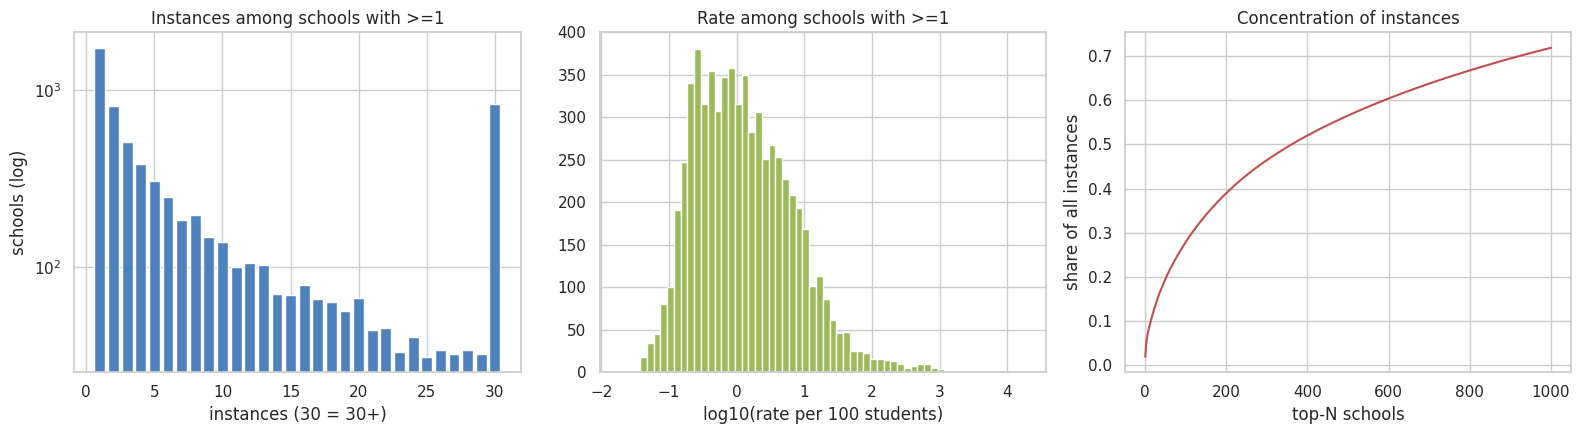

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
vc = pos.seclusion_instances.clip(upper=30).value_counts().sort_index()
ax[0].bar(vc.index.astype(int), vc.values, color='#4f81bd'); ax[0].set_yscale('log'); ax[0].set_xlabel('instances (30 = 30+)'); ax[0].set_ylabel('schools (log)'); ax[0].set_title('Instances among schools with >=1')
ax[1].hist(np.log10(pos.seclusion_rate), bins=60, color='#9bbb59'); ax[1].set_xlabel('log10(rate per 100 students)'); ax[1].set_title('Rate among schools with >=1')
ax[2].plot(np.arange(1, 1001), srt.values[:1000], color='#c0504d'); ax[2].set_xlabel('top-N schools'); ax[2].set_ylabel('share of all instances'); ax[2].set_title('Concentration of instances'); plt.tight_layout()

In [12]:
cols = ['sch_name','lea_name','lea_state','enrollment_total','seclusion_instances','seclusion_rate','sch_status_sped','sch_status_alt','jj']
print('Top 12 by instances'); display_top = df.nlargest(12, 'seclusion_instances')[cols]; print(display_top.to_string(index=False))
print('\nTop 12 by rate'); print(df.nlargest(12, 'seclusion_rate')[cols].to_string(index=False))

Top 12 by instances
                                              sch_name                                        lea_name lea_state  enrollment_total  seclusion_instances  seclusion_rate sch_status_sped sch_status_alt  jj
Yuma County Sheriff's Office-Second Chance High School                     Yuma County Sheriffs Office        AZ            11.000            2,058.000      18,709.091             Yes             No Yes
                 Eldora State Training School for Boys           Eldora State Training School for Boys        IA            52.000            1,408.000       2,707.692              No             No Yes
                                   River Street School                Capitol Region Education Council        CT           147.000            1,214.000         825.850             Yes             No  No
                  Developmental Learning Center-Warren Morris-Union Jointure Commisson School District        NJ           153.000            1,150.000         751.634 

## 4. Share reporting any seclusion and a threshold for "elevated" (checklist 4)

In [13]:
tiers = pd.DataFrame({'schools': [(x>=k).sum() for k in (1,2,3,5,10,20,50)], 'share_of_schools': [(x>=k).mean() for k in (1,2,3,5,10,20,50)],
                     'share_of_instances': [x[x>=k].sum()/x.sum() for k in (1,2,3,5,10,20,50)]}, index=[f'>= {k} instances' for k in (1,2,3,5,10,20,50)])
print(tiers.to_string())
# rate-based alternatives restricted to enrollment >= 30 (see section 9)
big = df[df.enrollment_total >= 30]
print('\nRate thresholds (enrollment >= 30): p90/p95/p99 among positives =', big[big.any_secl==1].seclusion_rate.quantile([.9,.95,.99]).round(2).to_dict())
print('Schools with rate >= 1 per 100 :', (big.seclusion_rate>=1).sum(), f'({(big.seclusion_rate>=1).mean():.2%})')
print('Schools with rate >= 5 per 100 :', (big.seclusion_rate>=5).sum(), f'({(big.seclusion_rate>=5).mean():.2%})')
print('Schools with >=5 instances AND rate >= 1 : ', ((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).sum(), f'({((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).mean():.2%})')

                 schools  share_of_schools  share_of_instances
>= 1 instances      6600             0.071               1.000
>= 2 instances      4861             0.052               0.984
>= 3 instances      4051             0.044               0.969
>= 5 instances      3161             0.034               0.941
>= 10 instances     2079             0.022               0.874
>= 20 instances     1230             0.013               0.765
>= 50 instances      438             0.005               0.538

Rate thresholds (enrollment >= 30): p90/p95/p99 among positives = {0.9: 10.17, 0.95: 19.48, 0.99: 100.31}
Schools with rate >= 1 per 100 : 3283 (3.65%)
Schools with rate >= 5 per 100 : 1268 (1.41%)
Schools with >=5 instances AND rate >= 1 :  2838 (3.16%)

In [14]:
# Is 'any' a one-off or a pattern? How does the share of schools with 1,2,3+ instances look within the positive group?
print((pos.seclusion_instances.clip(upper=10)).value_counts(normalize=True).sort_index().round(3).to_string())
# Which component drives it?
comp_tot = ana[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum()
print('\nInstance totals by student group:'); print((comp_tot/comp_tot.sum()).round(4).to_string())
print('\nSchools with any instance, by group:', {c.replace('seclusion_instances_',''): int((ana[c]>0).sum()) for c in comp_tot.index})

seclusion_instances
1.000    0.263
2.000    0.123
3.000    0.077
4.000    0.058
5.000    0.046
6.000    0.038
7.000    0.028
8.000    0.030
9.000    0.022
10.000   0.315

Instance totals by student group:
seclusion_instances_idea    0.815
seclusion_instances_504     0.011
seclusion_instances_wodis   0.174

Schools with any instance, by group: {'idea': 5697, '504': 356, 'wodis': 2423}

## 5. School types and grade levels (checklist 5)

In [15]:
df['type_sped']=df.sch_status_sped.eq('Yes'); df['type_alt']=df.sch_status_alt.eq('Yes'); df['type_charter']=df.sch_status_charter.eq('Yes')
df['type_magnet']=df.sch_status_magnet.eq('Yes'); df['type_jj']=df.jj.eq('Yes')
df['type_virtual_name'] = df.sch_name.str.contains(r'virtual|online|cyber|e-?learning|distance', case=False, na=False)   # name proxy; the real indicator (sch_virt_ind) is 'No' for every analysis-ready school, see section 2
df['regular'] = ~(df.type_sped | df.type_alt | df.type_jj)
# Plausibility rules (the cleaning flag_fte_outlier fires on only 1 school): FTE above enrollment, support FTE > 20 per 100 students, teachers > 50 per 100
fte_support = ['fte_counselors','fte_nurses','fte_psych','fte_social','fte_leo','fte_guards']
bad = df.flag_fte_outlier.copy()
for c in fte_support + ['fte_teachers']: bad |= (df[c] > df.enrollment_total).fillna(False)
for c in fte_support: bad |= (df[c]/df.enrollment_total*100 > 20).fillna(False)
bad |= (df.fte_teachers/df.enrollment_total*100 > 50).fillna(False)
df['fte_bad'] = bad
print('Schools with implausible FTE (notebook rules):', int(bad.sum()), '| flagged by cleaning flag_fte_outlier:', int(df.flag_fte_outlier.sum()))
df['enr_ge30'] = df.enrollment_total >= 30

def summ(d, by):
    g = d.groupby(by)
    out = pd.DataFrame({'schools': g.size(), 'pct_any_secl': g.any_secl.mean()*100,
        'mean_instances': g.seclusion_instances.mean(),
        'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
        'share_of_all_instances_%': g.seclusion_instances.sum()/d.seclusion_instances.sum()*100})
    return out

rows = []
for col, lab in [('type_sped','Special education'),('type_alt','Alternative'),('type_charter','Charter'),('type_magnet','Magnet'),('type_jj','Justice facility'),('type_virtual_name','Virtual (name proxy)')]:
    t_ = summ(df, col); t_.index = t_.index.map({True: 'Yes', False: 'No'})
    rows += [t_.loc[['Yes']].rename(index={'Yes': lab}), t_.loc[['No']].rename(index={'No': lab + ' = No'})]
type_tbl = pd.concat(rows); type_tbl

Schools with implausible FTE (notebook rules): 641 | flagged by cleaning flag_fte_outlier: 1

,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
Special education,1533,17.221,12.184,26.918,17.334
Special education = No,91561,6.920,0.973,0.975,82.666
Alternative,3850,1.844,0.577,5.455,2.061
Alternative = No,89244,7.316,1.183,1.060,97.939
Charter,7166,2.358,0.290,0.669,1.929
Charter = No,85928,7.484,1.230,1.089,98.071
Magnet,3995,4.280,0.477,0.514,1.769
Magnet = No,89099,7.216,1.188,1.089,98.231
Justice facility,839,4.648,5.147,26.733,4.007
Justice facility = No,92255,7.112,1.121,1.064,95.993


,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
grade_band,,,,,
elementary,36189,9.868,1.550,1.392,52.071
high,16884,3.364,0.497,0.273,7.780
middle,12839,5.514,0.526,0.487,6.261
other,182,9.341,3.473,18.274,0.587
span,27000,6.430,1.329,1.169,33.301


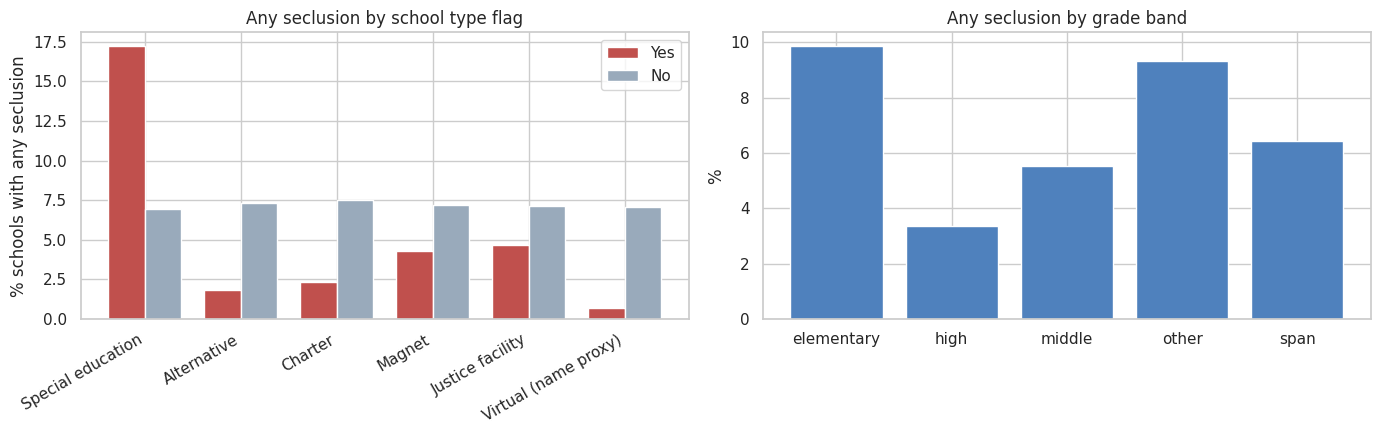

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
labs = ['Special education','Alternative','Charter','Magnet','Justice facility','Virtual (name proxy)']; cols = ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']
yes = [df.loc[df[c],'any_secl'].mean()*100 for c in cols]; no = [df.loc[~df[c],'any_secl'].mean()*100 for c in cols]
w=.38; i=np.arange(len(cols)); ax[0].bar(i-w/2, yes, w, label='Yes', color='#c0504d'); ax[0].bar(i+w/2, no, w, label='No', color='#9ab'); ax[0].set_xticks(i); ax[0].set_xticklabels(labs, rotation=30, ha='right'); ax[0].set_ylabel('% schools with any seclusion'); ax[0].legend(); ax[0].set_title('Any seclusion by school type flag')
gb = summ(df, 'grade_band'); ax[1].bar(gb.index, gb.pct_any_secl, color='#4f81bd'); ax[1].set_title('Any seclusion by grade band'); ax[1].set_ylabel('%')
plt.tight_layout(); gb

In [17]:
# Grade band within regular schools only (removes the special-ed / alternative / justice effect) and type x grade
print('Regular schools (not sped / alt / justice) by grade band'); print(summ(df[df.regular], 'grade_band').round(2).to_string())
print(f'\nShare of the {len(pos):,} schools with any seclusion that are...')
pos = df[df.any_secl==1]
print({k: f'{pos[k].mean():.1%} (vs {df[k].mean():.1%} of all schools)' for k in ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']})
print('\nRegular school share of positives:', f'{pos.regular.mean():.1%}')

Regular schools (not sped / alt / justice) by grade band
            schools  pct_any_secl  mean_instances  median_rate_if_any  share_of_all_instances_%
grade_band                                                                                     
elementary    35974         9.850           1.540               1.380                    64.450
high          14351         3.640           0.370               0.240                     6.160
middle        12671         5.520           0.500               0.480                     7.430
other            56         3.570           6.910             115.360                     0.450
span          24342         6.090           0.760               0.870                    21.510

Share of the 6,600 schools with any seclusion that are...
{'type_sped': '4.0% (vs 1.6% of all schools)', 'type_alt': '1.1% (vs 4.1% of all schools)', 'type_charter': '2.6% (vs 7.7% of all schools)', 'type_magnet': '2.6% (vs 4.3% of all schools)', 'type_jj': '0.6% (vs 0.

## 6. States and districts (checklist 6)

In [18]:
stt = df.groupby('lea_state').agg(schools=('combokey','size'), pct_any=('any_secl', lambda s: s.mean()*100), instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum'))
stt['instances_per_1000_students'] = stt.instances/stt.enroll*1000
stt['pct_missing_in_full_file'] = full.groupby('lea_state').flag_missing_seclusion.mean()*100
stt = stt.sort_values('pct_any', ascending=False)
print('Top 10 / bottom 12 states by % schools with any seclusion'); print(pd.concat([stt.head(10), stt.tail(12)]).round(2).to_string())
print('\nStates with 0 schools reporting any seclusion:', stt.index[stt.pct_any==0].tolist())
print('Median state % any:', round(stt.pct_any.median(),2), '| IQR', stt.pct_any.quantile([.25,.75]).round(2).tolist())

Top 10 / bottom 12 states by % schools with any seclusion
           schools  pct_any  instances        enroll  instances_per_1000_students  pct_missing_in_full_file
lea_state                                                                                                  
WI            2057   33.500  7,091.000   766,238.000                        9.250                     7.590
CT            1093   33.030  7,927.000   492,777.000                       16.090                     3.700
IA            1272   31.600  8,054.000   479,962.000                       16.780                     5.220
ME             553   28.030  2,378.000   160,928.000                       14.780                     3.150
WA            2280   25.000  8,879.000 1,043,411.000                        8.510                     6.480
KS            1282   22.460  5,541.000   449,432.000                       12.330                     7.100
VT             293   20.480    648.000    76,008.000                        8.

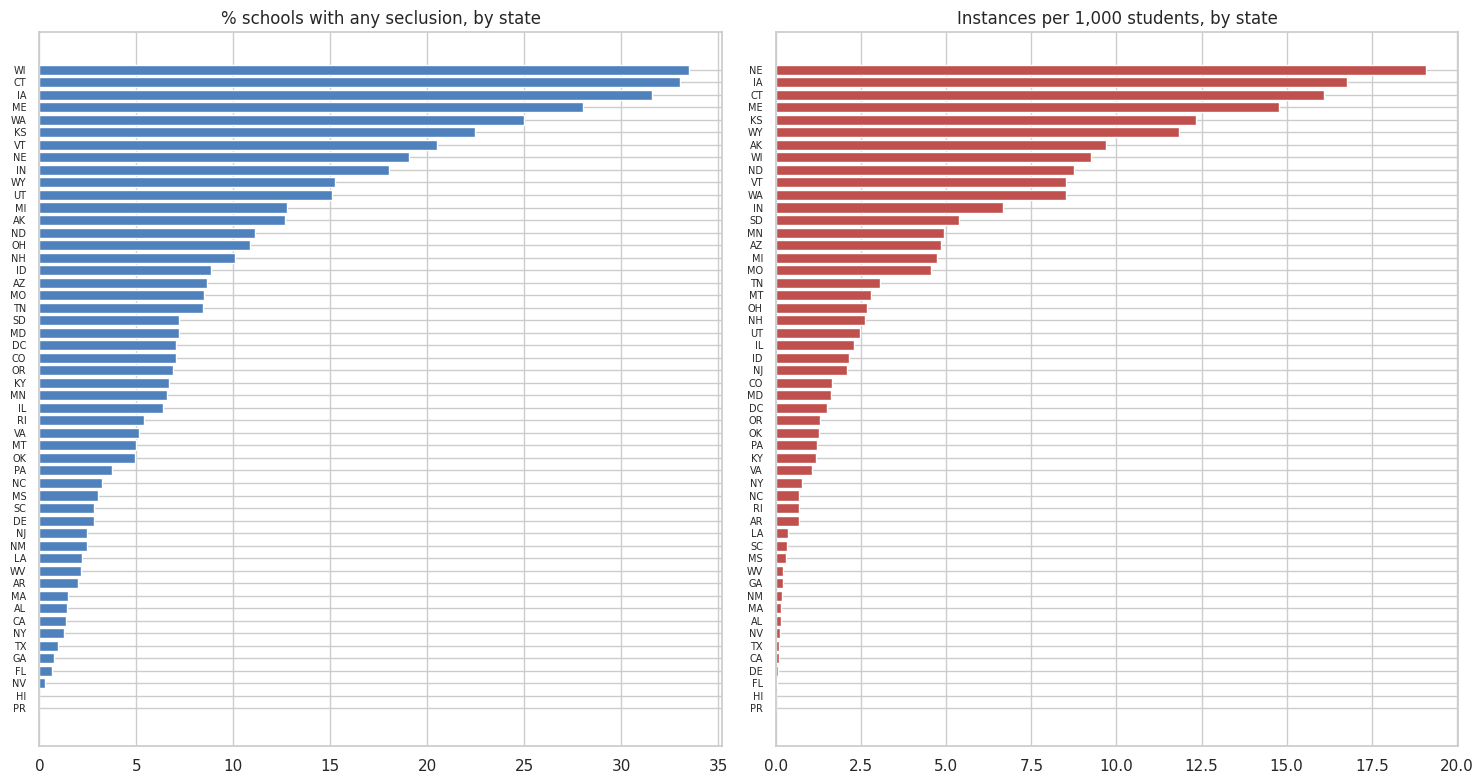

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
s = stt.sort_values('pct_any'); ax[0].barh(s.index, s.pct_any, color='#4f81bd'); ax[0].set_title('% schools with any seclusion, by state'); ax[0].tick_params(axis='y', labelsize=7)
s = stt.sort_values('instances_per_1000_students'); ax[1].barh(s.index, s.instances_per_1000_students, color='#c0504d'); ax[1].set_title('Instances per 1,000 students, by state'); ax[1].tick_params(axis='y', labelsize=7); plt.tight_layout()

Districts: 17,155; with >=1 school reporting any seclusion: 2,341 (13.6%)
Top  10 districts = 14.3% of instances
Top  50 districts = 33.8% of instances
Top 100 districts = 48.1% of instances
Top 500 districts = 83.0% of instances
Districts that account for 50% of instances: 110; for 80%: 431
                                                lea_name state  schools  schools_any  instances     enroll  share_instances_%  cum_share_%
leaid                                                                                                                                     
3172840                           LINCOLN PUBLIC SCHOOLS    NE       69           50  3,315.000 39,831.000              3.100        3.100
0400773                      Yuma County Sheriffs Office    AZ        1            1  2,058.000     11.000              1.900        5.000
0900700                 Capitol Region Education Council    CT       19           12  1,674.000  8,670.000              1.600        6.500
1999088     

(0.0, 10.0)

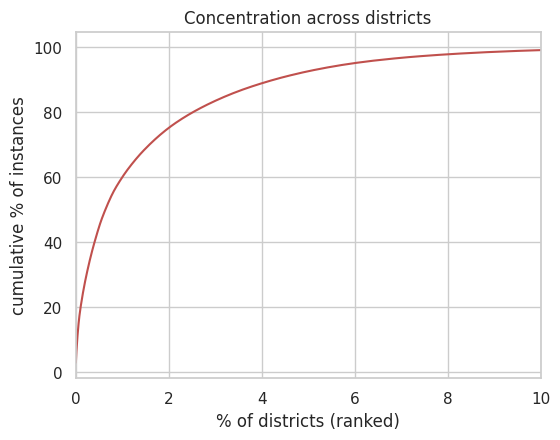

In [20]:
dist = df.groupby(['leaid']).agg(lea_name=('lea_name','first'), state=('lea_state','first'), schools=('combokey','size'), schools_any=('any_secl','sum'),
                                  instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum')).sort_values('instances', ascending=False)
dist['share_instances_%'] = dist.instances/dist.instances.sum()*100; dist['cum_share_%'] = dist['share_instances_%'].cumsum()
print(f'Districts: {len(dist):,}; with >=1 school reporting any seclusion: {(dist.schools_any>0).sum():,} ({(dist.schools_any>0).mean():.1%})')
for k in (10, 50, 100, 500): print(f'Top {k:>3} districts = {dist.instances.iloc[:k].sum()/dist.instances.sum():.1%} of instances')
print(f'Districts that account for 50% of instances: {(dist["cum_share_%"]<50).sum()+1}; for 80%: {(dist["cum_share_%"]<80).sum()+1}')
print(dist.head(15).round(1).to_string())
fig, ax = plt.subplots(figsize=(6,4.5)); d2 = dist[dist.instances>0]; ax.plot(np.arange(1,len(d2)+1)/len(dist)*100, d2['cum_share_%'].values, color='#c0504d'); ax.set_xlabel('% of districts (ranked)'); ax.set_ylabel('cumulative % of instances'); ax.set_title('Concentration across districts'); ax.set_xlim(0,10)

In [21]:
# Within-state vs between-state: how much of 'any seclusion' is explained by state alone, and by district?
from sklearn.metrics import roc_auc_score
st_mean = df.groupby('lea_state').any_secl.transform('mean'); print('AUC of state-mean alone    :', round(roc_auc_score(df.any_secl, st_mean),3))
lea_mean = df.groupby('leaid').any_secl.transform('mean'); print('AUC of district-mean (in-sample, optimistic, leaky):', round(roc_auc_score(df.any_secl, lea_mean),3))
print('Positives sitting in districts where >=50% of schools are positive:', f"{pos.leaid.map(df.groupby('leaid').any_secl.mean()).ge(.5).mean():.1%}")
print('Single-school districts among positives:', f"{(pos.leaid.map(df.groupby('leaid').size())==1).mean():.1%}")

AUC of state-mean alone    : 0.804
AUC of district-mean (in-sample, optimistic, leaky): 0.963
Positives sitting in districts where >=50% of schools are positive: 49.3%
Single-school districts among positives: 3.7%

## 7. Staffing and seclusion (checklist 7)
Per-100 ratios are rebuilt from the FTE counts, with rows flagged `flag_fte_outlier` excluded and ratios capped at the 99.5th percentile, because several FTE values are impossible (e.g. 19,048.6 psychologists at one school — see Data Issues).

In [22]:
st = df[~df.fte_bad & df.enrollment_total.ge(30)].copy()
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    st[f'{c}_p100'] = st[f'fte_{c}']/st.enrollment_total*100
    st[f'{c}_p100'] = st[f'{c}_p100'].clip(upper=st[f'{c}_p100'].quantile(.995))
# sanity: what is support_fte_per_100?
chk = (st.fte_counselors+st.fte_psych+st.fte_social+st.fte_nurses)/st.enrollment_total*100
print('support_fte_per_100 == counselors+psych+social+nurses per 100? corr =', round(np.corrcoef(chk.fillna(0), st.support_fte_per_100.fillna(0))[0,1],4), '| max abs diff on 99% of rows =', round((chk-st.support_fte_per_100).abs().quantile(.99),4))
staff = ['counselors','psych','social','nurses','leo','guards']
out = []
for c in staff:
    for lab, d in [('All (enr>=30)', st), ('Regular schools', st[st.regular])]:
        d = d.dropna(subset=[f'fte_{c}'])
        has = d[f'fte_{c}']>0
        pos_p = d.loc[has, f'{c}_p100']; terc = pd.qcut(pos_p, 3, labels=['low','mid','high'], duplicates='drop')
        r = {'staff': c, 'sample': lab, 'share_with_any_FTE_%': has.mean()*100, 'any_secl_%_none': d.loc[~has,'any_secl'].mean()*100}
        for t in ['low','mid','high']: r[f'any_secl_%_{t}'] = d.loc[pos_p.index[terc==t],'any_secl'].mean()*100
        out.append(r)
staff_tbl = pd.DataFrame(out).set_index(['staff','sample']); staff_tbl.round(2)

support_fte_per_100 == counselors+psych+social+nurses per 100? corr = 0.9265 | max abs diff on 99% of rows = 1.6949

share_with_any_FTE_%  any_secl_%_none  any_secl_%_low  any_secl_%_mid  any_secl_%_high
staff      sample                                                                                                 
counselors All (enr>=30)                  79.270            8.230           7.320           7.870            5.660
           Regular schools                80.200            8.070           7.310           7.970            5.750
psych      All (enr>=30)                  50.280            5.340           7.890           9.790            9.540
           Regular schools                50.720            5.350           7.890           9.880            9.350
social     All (enr>=30)                  39.530            6.070           8.100           9.580            9.270
           Regular schools                39.570            6.150           8.160           9.660            8.720
nurses     All (enr>=30)                  70.380            6.420           7.620           7.360            7.690
           Regular schools                71.310            6.630           7.680           7.290            7.400
leo        All (enr>=30)                  34.470            7.440           9.890           6.220            4.230
           Regular schools                34.820            7.440          10.030           6.230            4.140
guards     All (enr>=30)                  17.980            7.730           7.020           5.070            4.690
           Regular schools                17.800            7.740           7.140           5.220            4.320

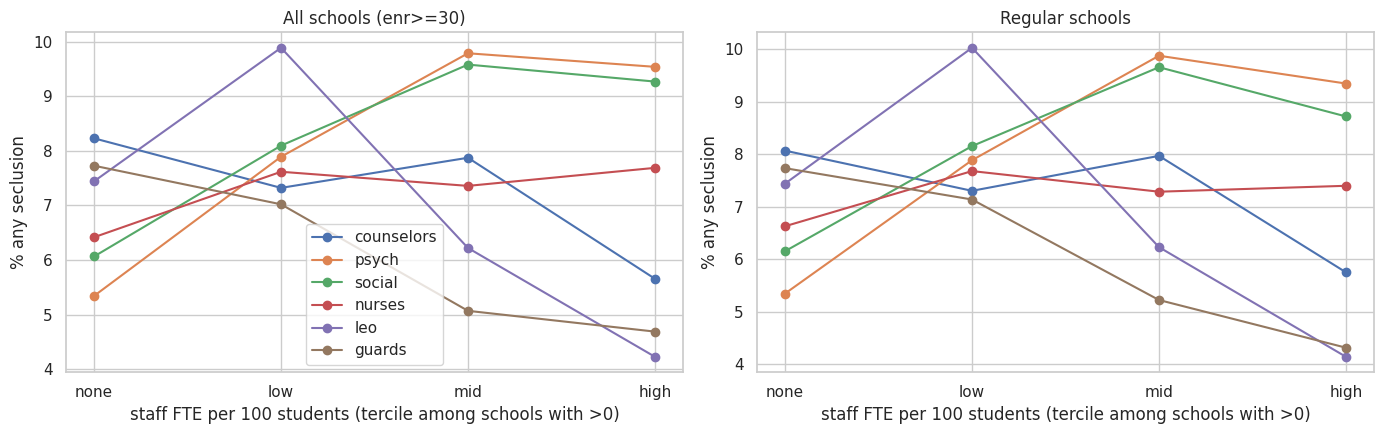

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lab, d) in zip(axes, [('All schools (enr>=30)', st), ('Regular schools', st[st.regular])]):
    for c in staff:
        dd = d.dropna(subset=[f'fte_{c}']); has = dd[f'fte_{c}']>0; pp = dd.loc[has, f'{c}_p100']; t = pd.qcut(pp, 3, labels=['low','mid','high'], duplicates='drop')
        vals = [dd.loc[~has,'any_secl'].mean()*100] + [dd.loc[pp.index[t==k],'any_secl'].mean()*100 for k in ['low','mid','high']]
        ax.plot(['none','low','mid','high'], vals, marker='o', label=c)
    ax.set_title(lab); ax.set_ylabel('% any seclusion'); ax.set_xlabel('staff FTE per 100 students (tercile among schools with >0)')
axes[0].legend(); plt.tight_layout()

In [24]:
# Staffing relationship after controlling for size, school type, grade band and population (logistic regression, standardised)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
X = st[st.regular].dropna(subset=['pct_idea']+[f'{c}_p100' for c in staff]).copy()
for c in ['pct_504','pct_el']:   # 19-23% missing in 2021-22: impute median + missing indicator instead of dropping
    X[c+'_na'] = X[c].isna().astype(float); X[c] = X[c].fillna(X[c].median())
feat = ['log_enr','pct_idea','pct_504','pct_el','pct_504_na','pct_el_na']+[f'{c}_p100' for c in staff]
X['log_enr'] = np.log(X.enrollment_total)
Xd = pd.concat([X[feat], pd.get_dummies(X.grade_band, drop_first=True, dtype=float)], axis=1)
m = LogisticRegression(max_iter=2000, C=1.0).fit(StandardScaler().fit_transform(Xd), X.any_secl)
coef = pd.Series(m.coef_[0], index=Xd.columns).sort_values(); print('Standardised log-odds coefficients (regular schools, enr>=30):'); coef.round(3)

Standardised log-odds coefficients (regular schools, enr>=30):

,0
high,-0.387
pct_el,-0.277
pct_504,-0.273
span,-0.209
middle,-0.202
pct_el_na,-0.179
guards_p100,-0.144
nurses_p100,-0.118
leo_p100,-0.116
other,-0.008


## 8. Student population and seclusion (checklist 8)

pct_idea
                size  pct_any
pct_idea_bin                 
(-0.1, 5.0]     2823    2.900
(5.0, 10.0]    15643    5.720
(10.0, 15.0]   32204    7.140
(15.0, 20.0]   21569    8.650
(20.0, 30.0]   10992    8.570
(30.0, 50.0]    1697    4.660
(50.0, 100.1]    279   15.050 

pct_504
                size  pct_any
pct_504_bin                  
(-0.1, 0.5]     7209    8.950
(0.5, 2.0]     22667    8.830
(2.0, 5.0]     23865    7.360
(5.0, 10.0]    13312    5.100
(10.0, 100.1]   4006    2.250 

pct_el
                size  pct_any
pct_el_bin                   
(-0.1, 1.0]     9983    7.250
(1.0, 5.0]     22999    8.720
(5.0, 15.0]    20350    8.400
(15.0, 40.0]   15192    6.690
(40.0, 100.1]   5467    3.950 

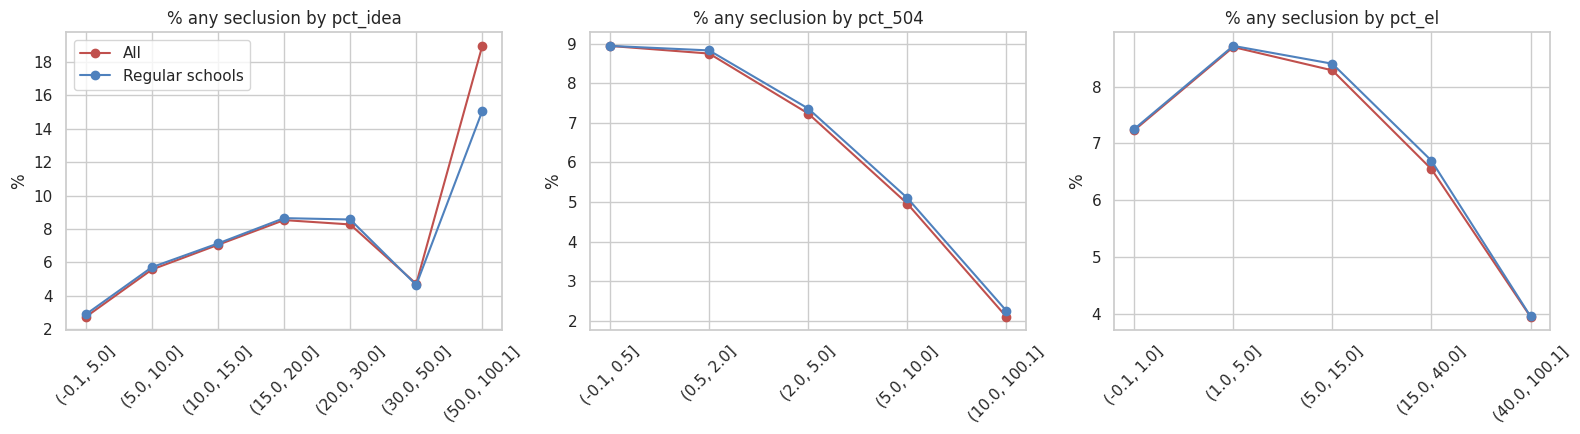

In [25]:
pp = df[df.enr_ge30].copy()   # each feature uses its own non-missing rows (pct_504 / pct_el are 19-23% missing)
bins = {'pct_idea':[-.1,5,10,15,20,30,50,100.1], 'pct_504':[-.1,.5,2,5,10,100.1], 'pct_el':[-.1,1,5,15,40,100.1]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5)); res = {}
for ax, (c, b) in zip(axes, bins.items()):
    pp[c+'_bin'] = pd.cut(pp[c], b)
    for lab, d, col in [('All', pp, '#c0504d'), ('Regular schools', pp[pp.regular], '#4f81bd')]:
        g = d.groupby(c+'_bin', observed=True).any_secl.agg(['mean','size']); ax.plot(g.index.astype(str), g['mean']*100, marker='o', label=lab, color=col); res[(c, lab)] = g
    ax.set_title(f'% any seclusion by {c}'); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('%')
axes[0].legend(); plt.tight_layout()
for k, v in res.items():
    if k[1]=='Regular schools': print(k[0]); print((v.assign(**{'pct_any': v['mean']*100}).drop(columns='mean')).round(2).to_string(), '\n')

In [26]:
sp = pp[['any_secl','pct_idea','pct_504','pct_el','seclusion_rate','enrollment_total']].copy(); sp['log_enr']=np.log(sp.enrollment_total)
print('Spearman with any_secl (all, enr>=30):'); print(sp.corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
r_ = pp[pp.regular]; print('\nSpearman with any_secl (regular schools):'); print(r_[['any_secl','pct_idea','pct_504','pct_el']].corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
print('\nRegular schools, any_secl by whether %IDEA is above regular-school median:', r_.groupby(r_.pct_idea>r_.pct_idea.median()).any_secl.mean().mul(100).round(2).to_dict())

Spearman with any_secl (all, enr>=30):
pct_idea            0.053
pct_504            -0.070
pct_el             -0.032
seclusion_rate      0.999
enrollment_total    0.003
log_enr             0.003

Spearman with any_secl (regular schools):
pct_idea    0.046
pct_504    -0.067
pct_el     -0.030

Regular schools, any_secl by whether %IDEA is above regular-school median: {False: 6.12, True: 8.36}

## 9. Small enrollments and rate distortion (checklist 9)
A single instance in a school of 10 students is a rate of 10 per 100. Rates for tiny schools are driven by the denominator.

                  schools  pct_any  median_rate_if_any  p95_rate_if_any  pct_rate_gt_100  pct_special_ed
enrollment_total                                                                                        
1-9                  1151    2.520              88.890        1,678.570            0.960          14.420
10-29                2104    3.800              63.960          833.480            1.620          14.450
30-99                5522    4.910              12.220          474.570            0.920           9.830
100-249             14559    5.820               2.170           30.760            0.090           2.150
250-499             34760    8.750               1.190           14.930            0.000           0.430
500-999             26712    6.870               0.610           10.460            0.000           0.180
1000+                8286    6.000               0.150            2.250            0.000           0.130

Schools under 30 students: 3,255 (3.5%); they hold 4.7

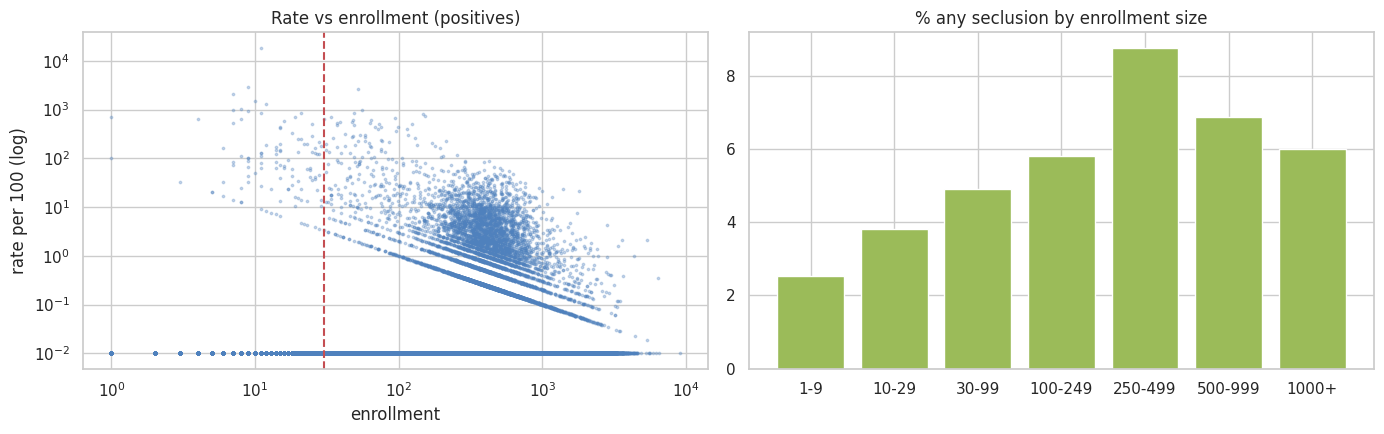

In [27]:
eb = pd.cut(df.enrollment_total, [0,9,29,99,249,499,999,1e6], labels=['1-9','10-29','30-99','100-249','250-499','500-999','1000+'])
g = df.groupby(eb, observed=True)
small = pd.DataFrame({'schools': g.size(), 'pct_any': g.any_secl.mean()*100,
    'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
    'p95_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].quantile(.95)),
    'pct_rate_gt_100': g.apply(lambda s: (s.seclusion_rate>100).mean()*100),
    'pct_special_ed': g.type_sped.mean()*100})
print(small.round(2).to_string())
print(f'\nSchools under 30 students: {(df.enrollment_total<30).sum():,} ({(df.enrollment_total<30).mean():.1%}); they hold {df.loc[df.enrollment_total<30,"seclusion_instances"].sum()/df.seclusion_instances.sum():.1%} of instances but {(df.loc[df.seclusion_rate>100].enrollment_total<30).mean():.0%} of rate>100 schools')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(df.enrollment_total, df.seclusion_rate.clip(lower=.01), s=3, alpha=.3, color='#4f81bd'); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('enrollment'); ax[0].set_ylabel('rate per 100 (log)'); ax[0].set_title('Rate vs enrollment (positives)'); ax[0].axvline(30, color='r', ls='--')
ax[1].bar(small.index.astype(str), small.pct_any, color='#9bbb59'); ax[1].set_title('% any seclusion by enrollment size'); plt.tight_layout()

In [28]:
# Candidate smoothing: empirical-Bayes-style shrinkage toward the overall rate, k = pseudo-students
m0 = df.seclusion_instances.sum()/df.enrollment_total.sum()*100
for k in (30, 100): df[f'rate_eb_k{k}'] = (df.seclusion_instances + k*m0/100)/(df.enrollment_total + k)*100
top = lambda col, n=100: set(df.nlargest(n, col).combokey)
print(f'Overall rate m0 = {m0:.2f} per 100')
for col in ['seclusion_rate','rate_eb_k30','rate_eb_k100']:
    t = df.nlargest(100, col); print(f'{col:>14}: median enrollment of top-100 = {t.enrollment_total.median():.0f}; share with enrollment<30 = {(t.enrollment_total<30).mean():.0%}; share sped = {t.type_sped.mean():.0%}')
print('\nOverlap of top-100 raw vs EB(k=30):', len(top('seclusion_rate') & top('rate_eb_k30')), '| min-enrollment-30 raw top-100 vs EB(k=30):', len(set(df[df.enr_ge30].nlargest(100,'seclusion_rate').combokey) & top('rate_eb_k30')))

Overall rate m0 = 0.23 per 100
seclusion_rate: median enrollment of top-100 = 37; share with enrollment<30 = 42%; share sped = 69%
   rate_eb_k30: median enrollment of top-100 = 53; share with enrollment<30 = 27%; share sped = 65%
  rate_eb_k100: median enrollment of top-100 = 64; share with enrollment<30 = 21%; share sped = 58%

Overlap of top-100 raw vs EB(k=30): 85 | min-enrollment-30 raw top-100 vs EB(k=30): 73

## 10. 2017-18 vs 2021-22 (checklist 10)
Schools present in both years (joined on `combokey`). A three-wave view with 2015-16 is added for context. **2020-21 was not supplied, so the COVID check is still open:** 2021-22 is a post-pandemic year (disrupted schooling, staffing shortages, remote/hybrid learning in some places), so changes from 2017-18 combine trend and pandemic effects. Virtual schools are absent from 2021-22 analysis-ready data (section 2).

2021-22 analysis-ready: 93,094 | 2017-18 analysis-ready: 91,013 | in both: 83,527 (89.7% of 2021-22, 91.8% of 2017-18)
Prevalence of any seclusion (all schools):  2017-18 6.56% | 2021-22 7.09%
Prevalence among schools in both years:      2017-18 6.79% | 2021-22 7.26%
Total instances: 2017-18 141,989 | 2021-22 107,755  (matched: 129,686 -> 94,738)

any_secl         any in 2021-22  none in 2021-22
any_18                                          
any in 2017-18             2442             3233
none in 2017-18            3619            74233

Persistence: P(any in 2021-22 | any in 2017-18) = 43.0% | P(any in 2021-22 | none in 2017-18) = 4.6%
Share of 2021-22 positives that were also positive in 2017-18: 40.3%
Spearman of instances across years: 0.383 | of rate per 100: 0.382

"Elevated" (>=5 instances and >=1 per 100), enr>=30 in both years: 2017-18 3.18% | 2021-22 3.24% | P(elev22 | elev18) = 36.1%
State prevalence correlation 2017-18 vs 2021-22: Pearson 0.974, Spearman 0.921

By 2017-1

,p18,p22,change
lea_state,,,
MD,12.000,7.200,-4.800
DC,10.200,7.000,-3.100
AL,3.900,1.400,-2.500
FL,2.600,0.600,-2.000
OR,8.800,6.900,-1.900
NE,15.400,19.100,3.600
WY,11.200,15.200,4.100
WA,20.100,25.000,4.900
SD,2.200,7.200,5.000


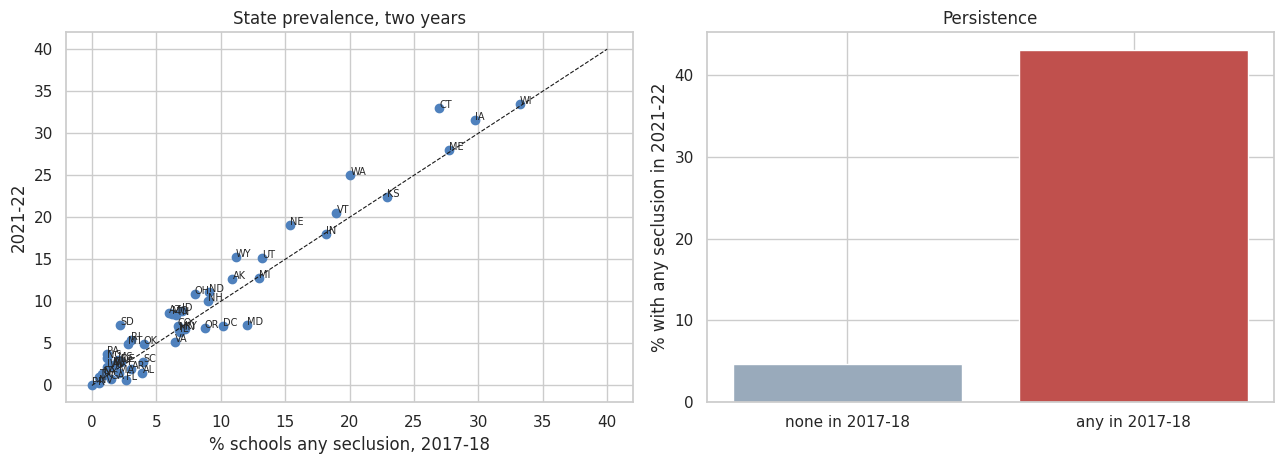

In [29]:
n17 = pd.read_csv(DATA_DIR/'schools_201718_analysis.csv', usecols=['combokey','seclusion_instances','enrollment_total','lea_state','seclusion_rate','sch_status_sped'], dtype={'combokey': str, 'lea_state': str})
j = df[['combokey','lea_state','seclusion_instances','enrollment_total','seclusion_rate','any_secl','sch_status_sped']].merge(n17, on='combokey', suffixes=('_22','_18'))
j['any_18'] = (j.seclusion_instances_18 > 0).astype(int)
print(f'2021-22 analysis-ready: {len(df):,} | 2017-18 analysis-ready: {len(n17):,} | in both: {len(j):,} ({len(j)/len(df):.1%} of 2021-22, {len(j)/len(n17):.1%} of 2017-18)')
print(f'Prevalence of any seclusion (all schools):  2017-18 {(n17.seclusion_instances>0).mean():.2%} | 2021-22 {df.any_secl.mean():.2%}')
print(f'Prevalence among schools in both years:      2017-18 {j.any_18.mean():.2%} | 2021-22 {j.any_secl.mean():.2%}')
print(f'Total instances: 2017-18 {n17.seclusion_instances.sum():,.0f} | 2021-22 {df.seclusion_instances.sum():,.0f}  (matched: {j.seclusion_instances_18.sum():,.0f} -> {j.seclusion_instances_22.sum():,.0f})')
tm = pd.crosstab(j.any_18.map({0:'none in 2017-18',1:'any in 2017-18'}), j.any_secl.map({0:'none in 2021-22',1:'any in 2021-22'})); print(); print(tm.to_string())
print(f'\nPersistence: P(any in 2021-22 | any in 2017-18) = {j.loc[j.any_18==1,"any_secl"].mean():.1%} | P(any in 2021-22 | none in 2017-18) = {j.loc[j.any_18==0,"any_secl"].mean():.1%}')
print(f'Share of 2021-22 positives that were also positive in 2017-18: {j.loc[j.any_secl==1,"any_18"].mean():.1%}')
print('Spearman of instances across years:', round(j[['seclusion_instances_18','seclusion_instances_22']].corr(method='spearman').iloc[0,1],3), '| of rate per 100:', round(j[['seclusion_rate_18','seclusion_rate_22']].corr(method='spearman').iloc[0,1],3))
big = j[(j.enrollment_total_18>=30)&(j.enrollment_total_22>=30)]
el18 = (big.seclusion_instances_18>=5)&(big.seclusion_rate_18>=1); el22 = (big.seclusion_instances_22>=5)&(big.seclusion_rate_22>=1)
print(f'\n"Elevated" (>=5 instances and >=1 per 100), enr>=30 in both years: 2017-18 {el18.mean():.2%} | 2021-22 {el22.mean():.2%} | P(elev22 | elev18) = {el22[el18].mean():.1%}')
s18 = n17.assign(a=n17.seclusion_instances>0).groupby('lea_state').a.mean()*100; s22 = df.groupby('lea_state').any_secl.mean()*100
sc = pd.concat([s18.rename('p18'), s22.rename('p22')], axis=1).dropna()
print(f'State prevalence correlation 2017-18 vs 2021-22: Pearson {sc.corr().iloc[0,1]:.3f}, Spearman {sc.corr(method="spearman").iloc[0,1]:.3f}')
sped = j.groupby('sch_status_sped_18').agg(schools=('combokey','size'), any_18=('any_18','mean'), any_22=('any_secl','mean')); print('\nBy 2017-18 special-ed status:'); print((sped*[1,100,100]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(sc.p18, sc.p22, color='#4f81bd'); [ax[0].annotate(k, (v.p18, v.p22), fontsize=7) for k, v in sc.iterrows()]
ax[0].plot([0, 40], [0, 40], 'k--', lw=.8); ax[0].set_xlabel('% schools any seclusion, 2017-18'); ax[0].set_ylabel('2021-22'); ax[0].set_title('State prevalence, two years')
pr = pd.Series({'none in 2017-18': j.loc[j.any_18==0,'any_secl'].mean()*100, 'any in 2017-18': j.loc[j.any_18==1,'any_secl'].mean()*100})
ax[1].bar(pr.index, pr.values, color=['#9ab', '#c0504d']); ax[1].set_ylabel('% with any seclusion in 2021-22'); ax[1].set_title('Persistence'); plt.tight_layout()
sc.assign(change=sc.p22-sc.p18).sort_values('change').round(1).iloc[[0,1,2,3,4,-5,-4,-3,-2,-1]]

In [30]:
# Three-wave view (2015-16, 2017-18, 2021-22)
r15 = pd.read_csv(DATA_DIR/'crdc_2015_16_analysis_ready.csv', usecols=['COMBOKEY','seclusion_instances','enrollment','flag_rate_undefined'], dtype={'COMBOKEY': str})
r15 = r15[~r15.flag_rate_undefined].rename(columns={'COMBOKEY':'combokey'}); r15['any_15'] = (r15.seclusion_instances>0).astype(int)
t = df[['combokey','any_secl']].rename(columns={'any_secl':'any_22'}).merge(n17.assign(any_18=(n17.seclusion_instances>0).astype(int))[['combokey','any_18']], on='combokey').merge(r15[['combokey','any_15']], on='combokey')
print(f'Overall prevalence: 2015-16 {r15.any_15.mean():.2%} -> 2017-18 {(n17.seclusion_instances>0).mean():.2%} -> 2021-22 {df.any_secl.mean():.2%}')
print(f'Balanced panel (schools valid in all three waves): {len(t):,}')
print('  prevalence by wave:', {k: f'{t[c].mean():.2%}' for k, c in [('2015-16','any_15'),('2017-18','any_18'),('2021-22','any_22')]})
k = t[['any_15','any_18','any_22']].sum(axis=1)
print('  waves with any seclusion (0/1/2/3):', k.value_counts().sort_index().to_dict(), '| share of ever-positive schools positive in all 3:', f'{(k==3).sum()/(k>0).sum():.1%}')
print('  P(any 2021-22 | any in both earlier waves) =', f"{t.loc[(t.any_15==1)&(t.any_18==1),'any_22'].mean():.1%}", '| P(any 2021-22 | none in both) =', f"{t.loc[(t.any_15==0)&(t.any_18==0),'any_22'].mean():.1%}")

Overall prevalence: 2015-16 5.50% -> 2017-18 6.56% -> 2021-22 7.09%
Balanced panel (schools valid in all three waves): 80,241
  prevalence by wave: {'2015-16': '5.73%', '2017-18': '6.89%', '2021-22': '7.40%'}
  waves with any seclusion (0/1/2/3): {0: 69262, 1: 7214, 2: 2447, 3: 1318} | share of ever-positive schools positive in all 3: 12.0%
  P(any 2021-22 | any in both earlier waves) = 60.2% | P(any 2021-22 | none in both) = 4.2%

## 11. Equity patterns (checklist 11, descriptive only)
**Race and sex breakdowns of secluded students are not in the cleaned files** (only total instances split by IDEA / Section 504 / no-disability). The disability split is shown below; race/sex needs the raw CRDC columns to be carried through cleaning (see Data Issues).

                   instances       students  instances_per_100_students  share_of_instances_%  share_of_students_%  rate_ratio_vs_no_disability
IDEA (disability) 56,336.000  5,680,820.000                       0.992                79.130               13.584                       24.939
Section 504 only   1,140.000  1,641,484.000                       0.069                 1.601                3.925                        1.747
No disability     13,718.000 34,498,264.000                       0.040                19.268               82.491                        1.000

Same, regular schools only:
      instances       students  instances_per_100_students
IDEA 55,702.000  5,616,090.000                       0.992
504   1,123.000  1,620,655.000                       0.069
None 13,514.000 34,219,439.000                       0.039

Note: counts are seclusion INSTANCES (events), not unique students; one student can account for many instances.

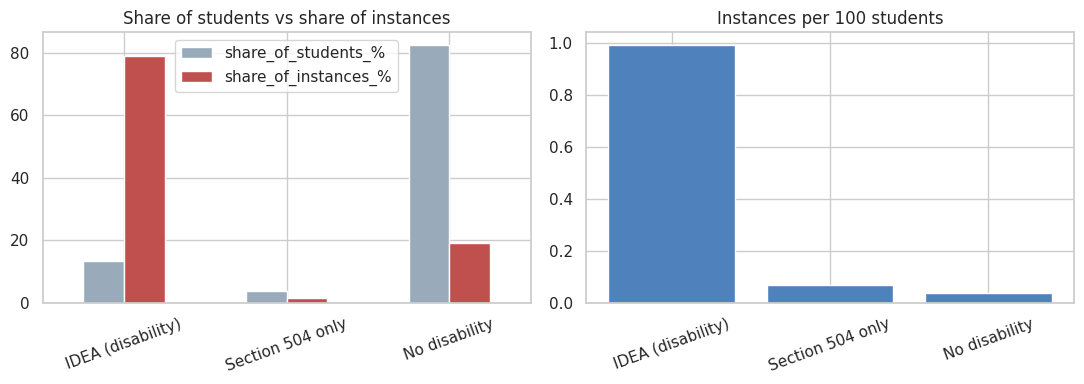

In [31]:
eq = df.dropna(subset=['enr_idea','enr_504','enrollment_total']).copy()
eq['enr_none'] = (eq.enrollment_total - eq.enr_idea - eq.enr_504).clip(lower=0)
def grp(inst, enr, d=eq):
    return pd.Series({'instances': d[inst].sum(), 'students': d[enr].sum(), 'instances_per_100_students': d[inst].sum()/d[enr].sum()*100})
equity = pd.DataFrame({'IDEA (disability)': grp('seclusion_instances_idea','enr_idea'), 'Section 504 only': grp('seclusion_instances_504','enr_504'), 'No disability': grp('seclusion_instances_wodis','enr_none')}).T
equity['share_of_instances_%'] = equity.instances/equity.instances.sum()*100; equity['share_of_students_%'] = equity.students/equity.students.sum()*100
equity['rate_ratio_vs_no_disability'] = equity.instances_per_100_students/equity.loc['No disability','instances_per_100_students']
print(equity.round(3).to_string())
excl = eq[~(eq.type_sped | eq.type_alt | eq.type_jj)]
eq2 = pd.DataFrame({'IDEA': grp('seclusion_instances_idea','enr_idea', excl), '504': grp('seclusion_instances_504','enr_504', excl), 'None': grp('seclusion_instances_wodis','enr_none', excl)}).T
print('\nSame, regular schools only:'); print(eq2.round(3).to_string())
print('\nNote: counts are seclusion INSTANCES (events), not unique students; one student can account for many instances.')
fig, ax = plt.subplots(1,2, figsize=(11,4)); equity[['share_of_students_%','share_of_instances_%']].plot.bar(ax=ax[0], color=['#9ab','#c0504d']); ax[0].set_title('Share of students vs share of instances'); ax[0].tick_params(axis='x', rotation=20)
ax[1].bar(equity.index, equity.instances_per_100_students, color='#4f81bd'); ax[1].set_title('Instances per 100 students'); ax[1].tick_params(axis='x', rotation=20); plt.tight_layout()

## 12. Correlations among candidate features (checklist 12)

,,rho
log_lea_enrollment,log_lea_schools,0.970
log_enrollment,fte_teachers,0.880
nurses_p100,support_fte_per_100,0.740
counselors_p100,fte_counselors,0.670
fte_teachers,fte_counselors,0.600
social_p100,support_fte_per_100,0.600
psych_p100,support_fte_per_100,0.590
log_enrollment,fte_counselors,0.560


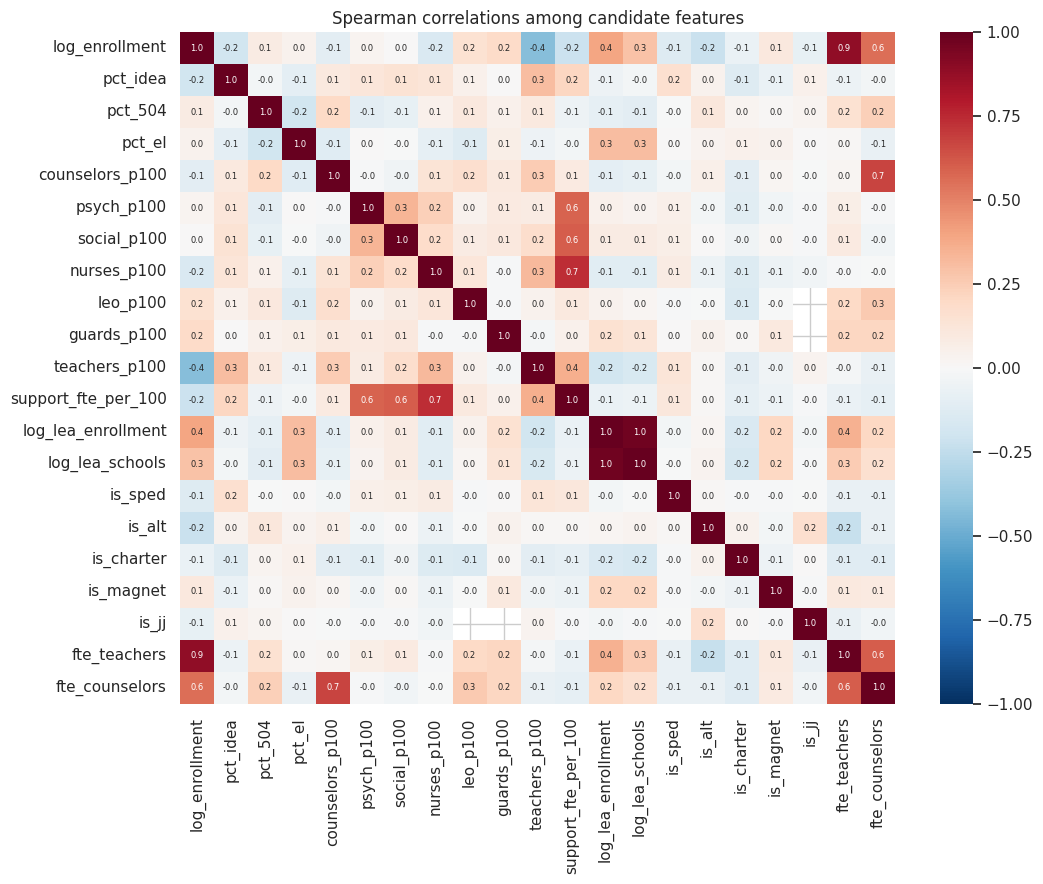

In [32]:
cand = df[df.enr_ge30 & ~df.fte_bad].copy()
cand['log_enrollment'] = np.log(cand.enrollment_total); cand['log_lea_enrollment'] = np.log(cand.lea_enrollment.clip(lower=1)); cand['log_lea_schools'] = np.log1p(cand.lea_schools)
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    cand[f'{c}_p100'] = (cand[f'fte_{c}']/cand.enrollment_total*100); cand[f'{c}_p100'] = cand[f'{c}_p100'].clip(upper=cand[f'{c}_p100'].quantile(.995))
for c in ['sped','alt','charter','magnet','jj']: cand[f'is_{c}'] = cand[f'type_{c}'].astype(int)
feats = ['log_enrollment','pct_idea','pct_504','pct_el','counselors_p100','psych_p100','social_p100','nurses_p100','leo_p100','guards_p100','teachers_p100','support_fte_per_100',
         'log_lea_enrollment','log_lea_schools','is_sped','is_alt','is_charter','is_magnet','is_jj','fte_teachers','fte_counselors']
corr = cand[feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size':6}, ax=ax); ax.set_title('Spearman correlations among candidate features'); plt.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename('rho'); pairs = pairs[pairs.abs()>=.5].sort_values(key=abs, ascending=False)
pairs.round(2)

## 13. Leakage review (checklist 13)

In [33]:
leak = pd.DataFrame([
 ('seclusion_instances_idea / _504 / _wodis', 'DIRECT LEAK', 'Components of the outcome (instances = their sum).'),
 ('seclusion_instances, seclusion_rate',        'DIRECT LEAK', 'The outcome itself / a deterministic transform of it.'),
 ('flag_missing_seclusion',                     'Exclude',     'Defines the sample; constant (False) in the analysis file.'),
 ('Other discipline measures (suspensions, expulsions, referrals, arrests)', 'POSSIBLE LEAK', 'Not in the cleaned files; same reporting module and same behavioural events. Exclude from the baseline model; if later tested, treat as a separate experiment.'),
 ('Restraint measures (mechanical / physical restraint)', 'POSSIBLE LEAK', 'Not in the cleaned files; reported together with seclusion in the same CRDC section; very likely co-reported. Exclude.'),
 ('fte_leo, fte_guards (security)',             'Reverse-causality risk', 'Schools with behaviour problems may hire security. Keep only if the model is framed as association, not prediction of future risk.'),
 ('lea_name, sch_name, leaid, combokey',        'Identifier', 'Not features. Use leaid only for grouped cross-validation.'),
], columns=['variable','status','why'])
print(leak.to_string(index=False))
print('\nAbsolute Spearman with any_secl, strongest first (enr>=30, no outliers):')
cc = cand[feats+['seclusion_instances_idea','seclusion_instances_wodis','seclusion_instances_504','any_secl']].corr(method='spearman')['any_secl'].drop('any_secl').abs().sort_values(ascending=False); print(cc.round(3).head(12).to_string())

                                                               variable                 status                                                                                                                                                            why
                               seclusion_instances_idea / _504 / _wodis            DIRECT LEAK                                                                                                             Components of the outcome (instances = their sum).
                                    seclusion_instances, seclusion_rate            DIRECT LEAK                                                                                                          The outcome itself / a deterministic transform of it.
                                                 flag_missing_seclusion                Exclude                                                                                                     Defines the sample; constant (False) in the

## 14. Baseline signal check: which feature groups carry information?
Grouped (by district) 5-fold cross-validation so schools of the same district never straddle train/test. Metric: ROC-AUC and average precision (the positive class is only ~6.6%, so AP matters). This is a signal check to inform the shortlist, not a final model.

In [34]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
mdl = cand.copy()
for c in ['pct_idea','pct_504','pct_el']: mdl[c+'_na'] = mdl[c].isna().astype(int)   # 2021-22: 4% / 23% / 19% missing; keep rows, add indicators
for c in ['fte_leo','fte_guards']: pass
mdl = pd.concat([mdl, pd.get_dummies(mdl.grade_band, prefix='gb', dtype=float)], axis=1)
gb_cols = [c for c in mdl.columns if c.startswith('gb_')]
size = ['log_enrollment']; typ = ['is_sped','is_alt','is_charter','is_magnet','is_jj']+gb_cols
pop = ['pct_idea','pct_504','pct_el','pct_idea_na','pct_504_na','pct_el_na']; staffc = ['counselors_p100','psych_p100','social_p100','nurses_p100','teachers_p100']; sec = ['leo_p100','guards_p100']
lea = ['log_lea_enrollment','log_lea_schools']
mdl = pd.concat([mdl, pd.get_dummies(mdl.lea_state, prefix='st', dtype=float)], axis=1); st_cols = [c for c in mdl.columns if c.startswith('st_')]
sets = {'A size only': size, 'B + type & grade': size+typ, 'C + population shares': size+typ+pop, 'D + staffing': size+typ+pop+staffc,
        'E + security staff': size+typ+pop+staffc+sec, 'F + district size': size+typ+pop+staffc+sec+lea, 'G + state (one-hot)': size+typ+pop+staffc+sec+lea+st_cols}
y = mdl.any_secl.values; groups = mdl.leaid.values; res = []
for name, cols_ in sets.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
    p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
    res.append({'feature set': name, 'n_features': len(cols_), 'ROC_AUC': roc_auc_score(y, p), 'avg_precision': average_precision_score(y, p)})
base = pd.DataFrame(res).set_index('feature set'); print(f'rows={len(mdl):,}; positive rate={y.mean():.3%} (AP baseline = positive rate)'); base.round(3)

rows=89,739; positive rate=7.218% (AP baseline = positive rate)

,n_features,ROC_AUC,avg_precision
feature set,,,
A size only,1,0.552,0.083
B + type & grade,11,0.643,0.114
C + population shares,17,0.673,0.130
D + staffing,22,0.695,0.148
E + security staff,24,0.701,0.157
F + district size,26,0.729,0.169
G + state (one-hot),78,0.830,0.348


In [35]:
# Permutation importance (AUC drop) for the F model on a held-out grouped split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance
cols_ = sets['F + district size']; tr, te = next(GroupShuffleSplit(1, test_size=.25, random_state=1).split(mdl, y, groups))
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0)).fit(mdl.iloc[tr][cols_], y[tr])
pi = permutation_importance(pipe, mdl.iloc[te][cols_], y[te], scoring='roc_auc', n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=cols_).sort_values(ascending=False); print('held-out AUC:', round(roc_auc_score(y[te], pipe.predict_proba(mdl.iloc[te][cols_])[:,1]),3)); imp.round(4)

held-out AUC: 0.744

,0
log_lea_enrollment,0.096
log_lea_schools,0.032
pct_504,0.024
log_enrollment,0.020
pct_idea,0.018
teachers_p100,0.017
gb_high,0.017
psych_p100,0.015
gb_elementary,0.012
pct_el,0.012


## 15. Data issues found during EDA (checklist deliverable 4)

In [36]:
issues = []
def add(i, sev, issue, n, detail): issues.append({'#': i, 'severity': sev, 'issue': issue, 'rows': n, 'detail': detail})
reg_ = df[df.regular]
virt = full[full.sch_virt_ind=='Yes']
add(1,'High','Virtual schools have no seclusion outcome and are dropped', int(virt.flag_missing_seclusion.sum()), f'{virt.flag_missing_seclusion.mean():.0%} of the {len(virt):,} virtual schools have a reserved seclusion code (mostly -9), so they are all excluded from the analysis-ready file and virtual vs non-virtual seclusion cannot be compared. Confirm -9 means "not applicable" for virtual schools; if so, consider a structural zero rather than NA.')
add(2,'High','Section 504 and English-learner counts heavily missing (-9)', int(full.enr_504.isna().sum()), f'enr_504 is {full.enr_504.isna().mean():.1%} missing and enr_el {full.enr_el.isna().mean():.1%} (vs under 0.3% in 2017-18); missingness is concentrated by state (IA, PR, SD, NM, MT for 504; MT, PR, WV, SD, VT for EL). EL-missing schools report less seclusion (4.8% vs 7.5%) and IDEA-missing schools far less (1.7% vs 7.2%), so the missingness is informative. pct_504 / pct_el are not usable as complete features.')
add(3,'High','FTE outlier flag is far too loose', int(df.fte_bad.sum()), f'flag_fte_outlier fires on {int(full.flag_fte_outlier.sum())} school, but {int(df.fte_bad.sum())} analysis-ready schools fail simple plausibility rules (FTE > enrollment, support FTE > 20 per 100, teachers > 50 per 100); e.g. fte_leo = 100 at {int((full.fte_leo==100).sum())} schools and teachers_per_100 up to {full.teachers_per_100.max():,.0f}. The QA report lists these top values but leaves them unchanged.')
add(4,'High','Extreme seclusion counts', int((df.seclusion_instances>df.enrollment_total).sum()), f'{int((df.seclusion_instances>df.enrollment_total).sum())} analysis-ready rows have more instances than students (max rate {df.seclusion_rate.max():,.0f} per 100: Yuma County Sheriff Second Chance High, AZ, 2,058 instances / 11 students); {int((reg_.seclusion_rate>25).sum())} regular schools exceed 25 per 100; max {df.seclusion_instances.max():,.0f} instances. Verify the top values against CRDC before using them as labels.')
add(5,'Med','Nonbinary counts almost never available', int(full.enr_nonbinary.isna().sum()), f'enr_nonbinary is {full.enr_nonbinary.isna().mean():.1%} missing, so the four flag_partial_* flags fire for about 97% of schools and carry no information. Totals (enrollment_total, enr_idea ...) can be slight undercounts. Replace the flags with one "nonbinary reported" indicator.')
add(6,'Med','Seclusion total blanked when any component is reserved', int(full.flag_missing_seclusion.sum()), f'The three components share the same reserved codes (4,905 each), so partial sums are not an issue here (unlike 2017-18). But 2,409 non-virtual schools (2.5%) are also missing the outcome; document the code mix for them (-9: 1,881, -13: 353, -5: 172, -3: 3) so suppressed (-13), skip (-9) and missing (-5) are not treated alike.')
add(7,'Med','Analysis-ready file includes non-digit IDs', int(ana.combokey.str.contains("[A-Za-z]").sum()), 'State-operated program IDs such as 24SOP02 are kept as reported (25 schools; 14 in the analysis file); the QA report leaves the keep/drop decision open. They are not joinable to 2017-18 by number.')
add(8,'Med','Open mapping and definitions', 9, 'QA report: 9 mapping rows unresolved; TOT_ENR_* may include preschool and can be partial sums (reserved codes treated as zero upstream); JJ not in Appendix Sheet B; counts were perturbed by one case (small counts are noisy). Resolve before pooling years.')
add(9,'Med','Tiny enrollments', int((df.enrollment_total<10).sum()), 'flag_small_enrollment (under 10) is not applied in the analysis file and is too low for rates (see section 9).')
add(10,'Low','Dead flags', 2, 'flag_missing_module and flag_missing_lea never fire (as in 2017-18); flag_missing_seclusion and flag_missing_enrollment are constant False in the analysis file.')
add(11,'Low','seclusion_rate naming and units', len(df), 'Instances per 100 students (can exceed 100); rename to seclusion_instances_per_100 across years.')
add(12,'Med','Race / sex of secluded students and other discipline / restraint columns not carried through', 0, 'Needed for the equity and leakage checklist items.')
add(13,'Med','State coverage and reporting practice', 0, f'{full.lea_state.nunique()} state codes (incl. DC and PR). Hawaii and Puerto Rico report no seclusion; NV, FL, GA, TX, NY, CA are near or under ~1.5%, so cross-state differences mix real practice with state law and reporting definitions (same pattern in 2015-16 and 2017-18).')
add(14,'Low','2020-21 not supplied', 0, 'The COVID check in the checklist needs the 2020-21 cleaned file.')
pd.DataFrame(issues).set_index('#')

,severity,issue,rows,detail
#,,,,
1,High,Virtual schools have no seclusion outcome and are dropped,2496,"100% of the 2,496 virtual schools have a reserved seclusion code (mostly -9), so they are all excluded from the analysis-ready file and virtual vs non-virtual seclusion cannot be compared. Confirm -9 means ""not applicable"" for virtual schools; if so, consider a structural zero rather than NA."
2,High,Section 504 and English-learner counts heavily missing (-9),22169,"enr_504 is 22.6% missing and enr_el 18.8% (vs under 0.3% in 2017-18); missingness is concentrated by state (IA, PR, SD, NM, MT for 504; MT, PR, WV, SD, VT for EL). EL-missing schools report less seclusion (4.8% vs 7.5%) and IDEA-missing schools far less (1.7% vs 7.2%), so the missingness is informative. pct_504 / pct_el are not usable as complete features."
3,High,FTE outlier flag is far too loose,641,"flag_fte_outlier fires on 1 school, but 641 analysis-ready schools fail simple plausibility rules (FTE > enrollment, support FTE > 20 per 100, teachers > 50 per 100); e.g. fte_leo = 100 at 11 schools and teachers_per_100 up to 4,958. The QA report lists these top values but leaves them unchanged."
4,High,Extreme seclusion counts,110,"110 analysis-ready rows have more instances than students (max rate 18,709 per 100: Yuma County Sheriff Second Chance High, AZ, 2,058 instances / 11 students); 162 regular schools exceed 25 per 100; max 2,058 instances. Verify the top values against CRDC before using them as labels."
5,Med,Nonbinary counts almost never available,95656,"enr_nonbinary is 97.6% missing, so the four flag_partial_* flags fire for about 97% of schools and carry no information. Totals (enrollment_total, enr_idea ...) can be slight undercounts. Replace the flags with one ""nonbinary reported"" indicator."
6,Med,Seclusion total blanked when any component is reserved,4905,"The three components share the same reserved codes (4,905 each), so partial sums are not an issue here (unlike 2017-18). But 2,409 non-virtual schools (2.5%) are also missing the outcome; document the code mix for them (-9: 1,881, -13: 353, -5: 172, -3: 3) so suppressed (-13), skip (-9) and missing (-5) are not treated alike."
7,Med,Analysis-ready file includes non-digit IDs,14,State-operated program IDs such as 24SOP02 are kept as reported (25 schools; 14 in the analysis file); the QA report leaves the keep/drop decision open. They are not joinable to 2017-18 by number.
8,Med,Open mapping and definitions,9,QA report: 9 mapping rows unresolved; TOT_ENR_* may include preschool and can be partial sums (reserved codes treated as zero upstream); JJ not in Appendix Sheet B; counts were perturbed by one case (small counts are noisy). Resolve before pooling years.
9,Med,Tiny enrollments,1151,flag_small_enrollment (under 10) is not applied in the analysis file and is too low for rates (see section 9).


## 16. Key findings (2021-22)
1. **Data are consistent with the QA report and complete enough, with one structural hole.** 98,010 schools; 93,094 (95.0%) are analysis-ready. The cleaning log reconciles exactly with the NaNs in the schools file (all 14 columns, difference 0). The outcome is missing for 4,905 schools (5.0%): -9 structural skips 4,377, suppressed -13 353, -5 172, -3 3. **All 2,496 virtual schools are among them** (50.9% of the missing), so the analysis-ready file contains no virtual schools and virtual vs non-virtual seclusion cannot be compared. Dropped schools are smaller (median 258 vs 412 students) and more often special-education (5.6% vs 1.6%).
2. **Seclusion is rare and extremely skewed.** 92.9% of schools report zero; 7.09% (6,600) report at least one instance (5.50% in 2015-16, 6.56% in 2017-18). Among those, the median is 4 instances, the 90th percentile 36 and the maximum 2,058. The top 100 schools hold 27.8% of instances (39.8% in 2015-16, 30% in 2017-18); 110 schools exceed 100 instances per 100 students.
3. **State reporting context dominates.** Wisconsin, Connecticut, Iowa, Maine, Washington and Kansas have 22-34% of schools reporting any seclusion; Florida, Georgia, Texas, California and New York are near or under 1.5%; Hawaii and Puerto Rico report none. State alone gives ROC-AUC 0.80, and adding it to the baseline lifts average precision from 0.17 to 0.35.
4. **Concentrated in few districts, less than before.** 13.6% of districts have any school reporting seclusion; 110 districts hold half of all instances and 431 hold 80% (70 and 291 in 2015-16). Single-school outliers matter: Yuma County Sheriff's Second Chance High (AZ) reports 2,058 instances for 11 students.
5. **School type.** Special-education schools: 17.2% report any (vs 6.9%) and hold 17.3% of instances while being 1.6% of schools; justice facilities 4.6% (7.9% in 2017-18); alternative 1.8%, charter 2.4%, magnet 4.3%. Elementary 9.9%, span 6.4%, middle 5.5%, high 3.4%. 94.7% of positive schools are ordinary schools.
6. **Student population.** %IDEA is the clearest positive correlate (2.9% any under 5% IDEA, about 8.6% at 15-30%, falling above 30%); %504 is the strongest negative (8.9% at 0.5% or less, 2.3% at 10% or more); %EL is inverted-U. All rank correlations with the outcome are weak (|rho| <= 0.07). Section 504 and EL counts are 22.6% and 18.8% missing (-9, concentrated in states such as IA, PR, SD, NM, MT), and the missingness is informative (EL-missing 4.8% vs 7.5%), so use missing indicators rather than dropping rows.
7. **Staffing.** Non-monotonic and confounded. Psychologists and social workers are positively associated after adjustment; security guards, nurses and law-enforcement FTE negative; counselors about zero. The cleaning outlier flag catches 1 school, but 641 fail simple plausibility rules, and those rows are excluded from staffing analysis here.
8. **Small enrollments distort rates.** Schools under 30 students are 3.5% of schools and 4.7% of instances but 41% of the schools with rates above 100 per 100. Median rate among positives is 89 for enrollments of 1-9 and 12 for 30-99, versus 1.2 for 250-499. Use a minimum of 30 plus shrinkage (k about 30-100).
9. **2017-18 vs 2021-22 (83,527 schools in both).** Prevalence rose from 6.79% to 7.26% in the matched set, while total instances fell 27% (129,686 to 94,738): more schools report some seclusion, but fewer instances overall. Persistence is high: 43.0% of schools with any in 2017-18 also have any in 2021-22 vs 4.6% of the others; 36.1% of elevated schools stay elevated. State prevalence is nearly identical (r = 0.97); the biggest rises are CT, SD, WA, WY and NE, the biggest falls MD, DC, AL and FL. Across three waves (80,241 schools valid in all): 5.73% to 6.89% to 7.40%; 60.2% of schools positive in both earlier waves are positive again vs 4.2% of those never positive. The 2020-21 COVID check is still open (file not supplied).
10. **Equity (disability only).** Students with IDEA are 13.6% of enrolled students but account for 79.1% of instances: 0.99 instances per 100 students vs 0.040 for students without a disability (25x); Section 504-only students 0.069 (1.7x). These are events, not unique students. Race and sex could not be assessed from the cleaned file.
11. **Redundant features.** District enrollment and district school count (rho 0.97); school enrollment and teacher FTE (0.88); nurses per 100 and the combined support ratio (0.74); counselors per 100 and counselor FTE (0.67).
12. **Leakage.** The three seclusion components and the rate are the outcome. Restraint and other discipline measures are not in the cleaned file so could not be tested here; in 2015-16 physical restraint was a strong leak (AUC 0.84 alone), so exclude them by default.

## 17. Recommended target definition
| | Definition | Prevalence | Use |
|---|---|---|---|
| **Primary: `any_seclusion`** | `seclusion_instances >= 1` | 7.1% of analysis-ready schools | Main classification target. Robust to enrollment, avoids the unstable rate. |
| **Secondary: `elevated_seclusion`** | `seclusion_instances >= 5` **and** `seclusion_rate >= 1` (per 100 students) | 3.2% of schools with enrollment >= 30 | Sensitivity analysis. Five instances covers 94% of instances and removes one-off events; the rate floor stops large schools qualifying on volume alone. |
| Not recommended | Raw rate or raw count as regression target | | 93% zeros, heavy tail (max 18,709 per 100), denominator-driven for small schools. |

These are the same definitions as for 2015-16 and 2017-18, so models can be compared or pooled across years. **Modeling frame:** analysis-ready, enrollment >= 30 (drops 3,255 schools, 3.5%), excluding schools with implausible FTE (641, notebook rules), grouped cross-validation by `leaid`. Keep rows with missing %504 / %EL / %IDEA and add missing indicators. Virtual schools cannot be modeled (no outcome). If years are pooled, add a year indicator and a state effect.

In [37]:
shortlist = pd.DataFrame([
 ('log(enrollment_total)', 'Size', 'Include', 'Scale effect; instances scale with students.'),
 ('grade_band', 'School type', 'Include', 'Elementary 9.9% vs high 3.4% any seclusion; holds in regular schools.'),
 ('sch_status_sped', 'School type', 'Include', '17.2% vs 6.9% any; 17.3% of instances.'),
 ('sch_status_alt', 'School type', 'Include', 'Lower rate, distinct population.'),
 ('sch_status_charter', 'School type', 'Include', '2.4% vs 7.5% any.'),
 ('jj (justice facility)', 'School type', 'Include', 'Small group (839) with extreme counts when positive.'),
 ('sch_status_magnet', 'School type', 'Optional', 'Weak permutation importance.'),
 ('pct_idea (+ pct_idea_na)', 'Population', 'Include', 'Clearest positive correlate; add indicator for the 4.2% missing (informative).'),
 ('pct_504 (+ pct_504_na)', 'Population', 'Include', 'Strongest negative correlate and high permutation importance; 22.6% missing, so keep rows and add an indicator.'),
 ('pct_el (+ pct_el_na)', 'Population', 'Include', 'Inverted-U; 18.8% missing and informative; use indicator.'),
 ('psych per 100, social per 100', 'Staffing', 'Include', 'Positive association after adjustment; cap per-100 ratios at the 99.5th percentile and drop implausible-FTE schools.'),
 ('counselors per 100, nurses per 100, teachers per 100', 'Staffing', 'Optional', 'Small adjusted effects; teachers per 100 is unstable for tiny schools.'),
 ('fte_leo / fte_guards per 100', 'Security', 'Optional (caution)', 'Negative association; likely reverse causality. fte_leo is only 0.9% missing in 2021-22.'),
 ('log(lea_enrollment)', 'District context', 'Include', 'Top permutation importance among context features; drop lea_schools (rho 0.97).'),
 ('lea_state (categorical / region)', 'Context', 'Include in a second model', 'Dominant signal (AUC 0.73 -> 0.83); reflects state law and reporting practice. Run with and without.'),
 ('fte_teachers, fte_counselors (raw counts)', 'Staffing', 'Drop', 'Redundant with enrollment (rho 0.88 / 0.56).'),
 ('support_fte_per_100', 'Staffing', 'Drop', 'Composite of components already included; its derivation does not equal the sum of the four ratios (corr 0.93).'),
 ('lea_schools', 'District context', 'Drop', 'rho 0.97 with log(lea_enrollment).'),
 ('enr_nonbinary, flag_partial_*', 'Population', 'Drop', 'Nonbinary count 97.6% missing; partial flags fire for ~97% of schools and carry no information.'),
 ('sch_virt_ind', 'School type', 'Not usable', 'All 2,496 virtual schools lack the outcome and are outside the analysis-ready file.'),
 ('seclusion_instances_idea/_504/_wodis, seclusion_instances, seclusion_rate', 'Outcome', 'EXCLUDE (leak)', 'Components or transforms of the target.'),
 ('Restraint and other discipline measures', 'Behaviour', 'EXCLUDE (leak risk)', 'Not in file; physical restraint leaked strongly in 2015-16 (AUC 0.84 alone).'),
 ('leaid, schid, combokey, names', 'Identifier', 'Not features', 'Use leaid for grouped CV only.'),
], columns=['feature','group','decision','reason'])
shortlist

,feature,group,decision,reason
0,log(enrollment_total),Size,Include,Scale effect; instances scale with students.
1,grade_band,School type,Include,Elementary 9.9% vs high 3.4% any seclusion; holds in regular schools.
2,sch_status_sped,School type,Include,17.2% vs 6.9% any; 17.3% of instances.
3,sch_status_alt,School type,Include,"Lower rate, distinct population."
4,sch_status_charter,School type,Include,2.4% vs 7.5% any.
5,jj (justice facility),School type,Include,Small group (839) with extreme counts when positive.
6,sch_status_magnet,School type,Optional,Weak permutation importance.
7,pct_idea (+ pct_idea_na),Population,Include,Clearest positive correlate; add indicator for the 4.2% missing (informative).
8,pct_504 (+ pct_504_na),Population,Include,"Strongest negative correlate and high permutation importance; 22.6% missing, so keep rows and add an indicator."
9,pct_el (+ pct_el_na),Population,Include,Inverted-U; 18.8% missing and informative; use indicator.


In [38]:
OUT_DIR = Path('/mnt/user-data/outputs'); OUT_DIR.mkdir(parents=True, exist_ok=True)
shortlist.to_csv(OUT_DIR/'feature_shortlist_202122.csv', index=False)
pd.DataFrame(issues).to_csv(OUT_DIR/'data_issues_202122.csv', index=False)
frame = df[(df.enrollment_total >= 30) & ~df.fte_bad].copy()
frame['elevated_seclusion'] = ((frame.seclusion_instances >= 5) & (frame.seclusion_rate >= 1)).astype(int)
print(f"Modeling frame: {len(frame):,} schools | any_seclusion prevalence {frame.any_secl.mean():.2%} | elevated_seclusion prevalence {frame.elevated_seclusion.mean():.2%} ({frame.elevated_seclusion.sum():,} schools)")
print('Schools under 30 students dropped:', int((df.enrollment_total < 30).sum()))

Modeling frame: 89,739 schools | any_seclusion prevalence 7.22% | elevated_seclusion prevalence 3.15% (2,830 schools)
Schools under 30 students dropped: 3255